# Image data visualizer

### Dimitra Giantsidi & Nolan Ottele 2026

Displays the .fits (matched-filter and Segment) and .png (2D exponential fit, stream fitting and
length-to-width ratio vs. declination graph) image files of a galaxy in all angles that are saved.

In [14]:
# import all necessary libraries
import matplotlib.pyplot as plt
from IPython.display import Image, display
from astropy.io import fits
from astropy.wcs import WCS
from astropy.visualization import astropy_mpl_style
from pathlib import Path as path
import numpy as np
from scipy.ndimage import gaussian_filter
import matplotlib.colors as mcolors
from matplotlib.colors import ListedColormap
import colorsys

In [15]:
# define the desired galaxy, its depth and distance
box = 'storm'
num = '2'
galaxy_name = f'{box}_{num}'
depth = '26p5'
distance = 2000

In [16]:
# define the matchedi-filter outputs path
mf_catalogs_path = path(f'../matched_filter/mf_data/mf_catalogs/{depth}_{distance}/{galaxy_name}')

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=0.0_a=0.0_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


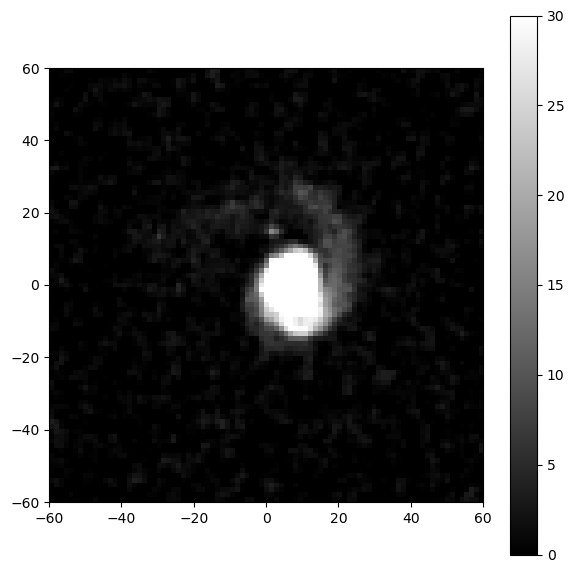

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=17.0_a=222.5_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


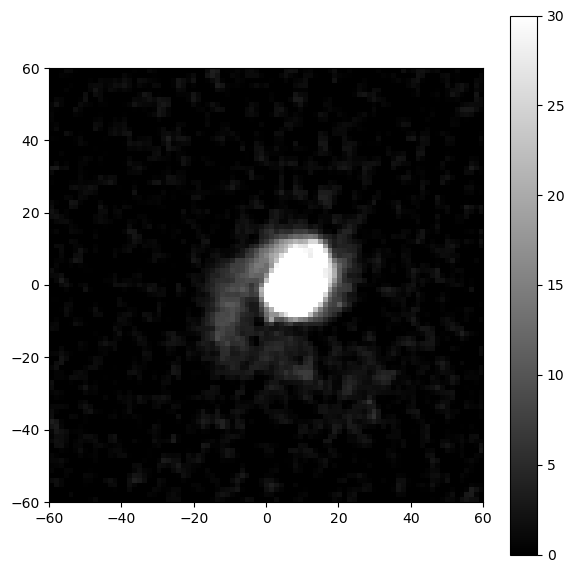

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=24.1_a=85.0_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


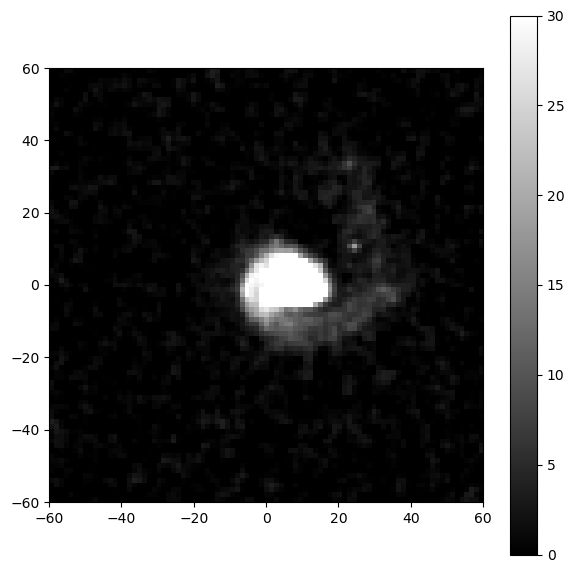

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=29.6_a=307.5_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


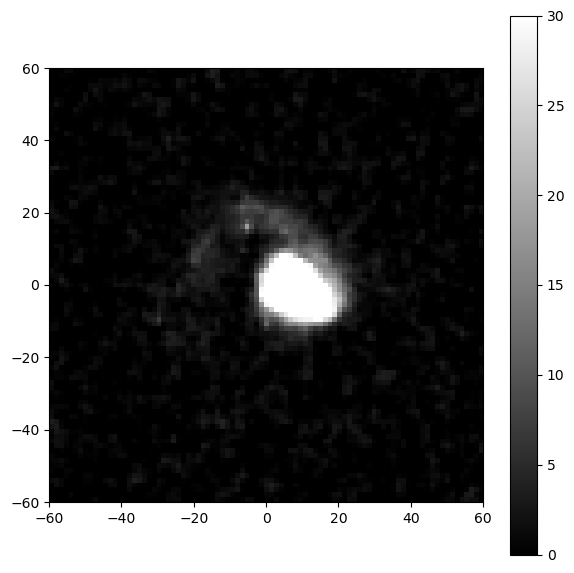

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=34.3_a=170.0_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


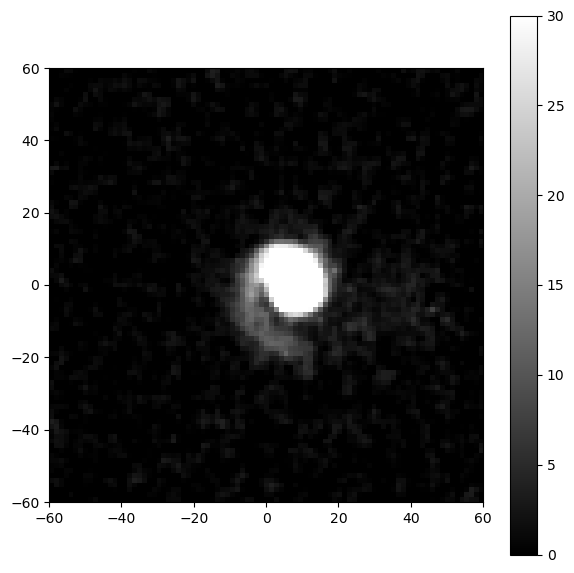

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=38.5_a=32.5_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


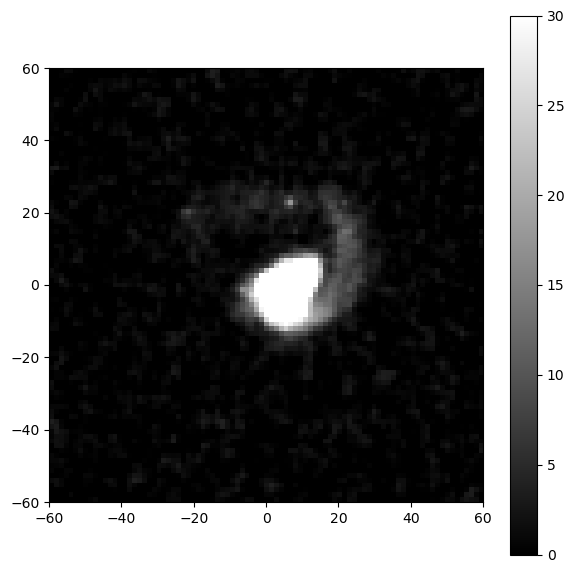

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=42.3_a=255.0_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


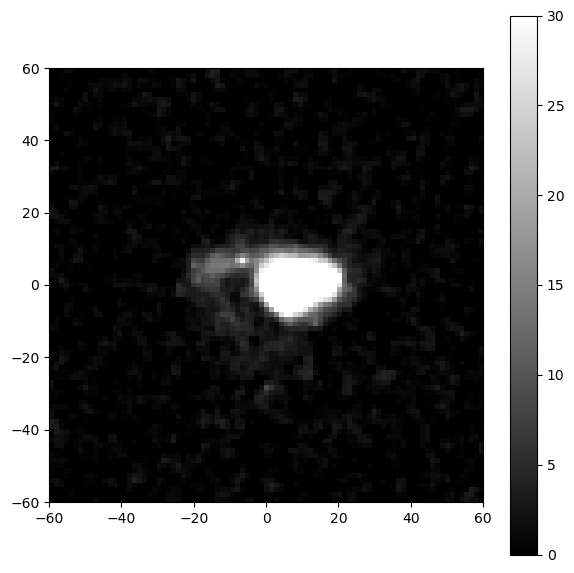

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=45.9_a=117.4_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


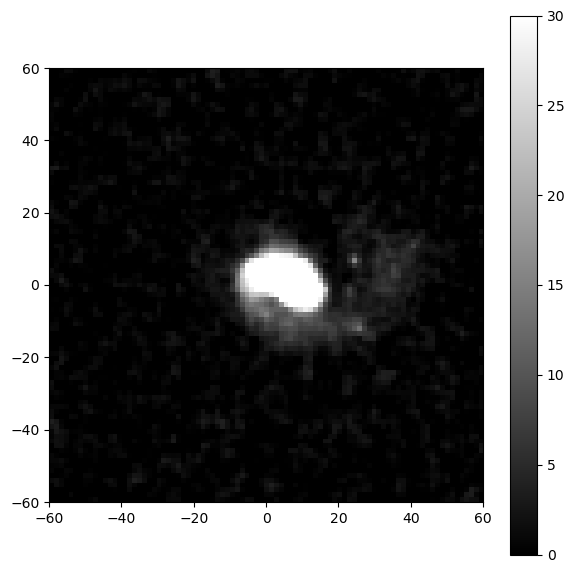

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=49.3_a=339.9_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


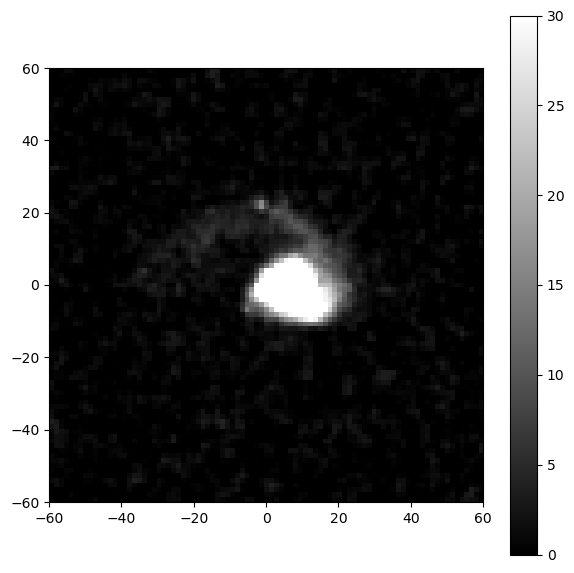

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=52.5_a=202.4_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


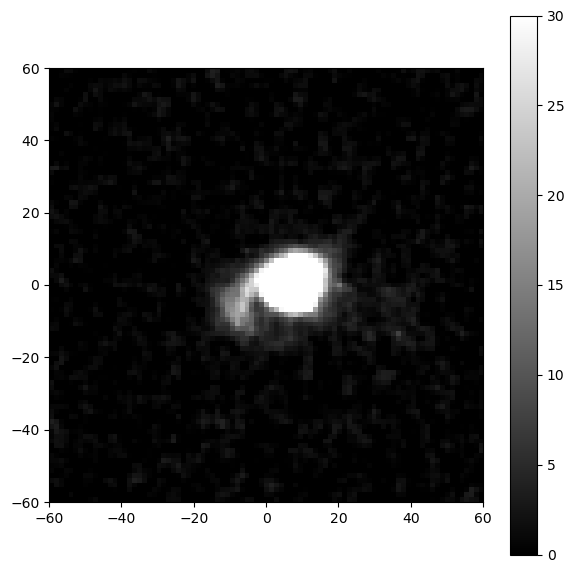

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=55.6_a=64.9_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


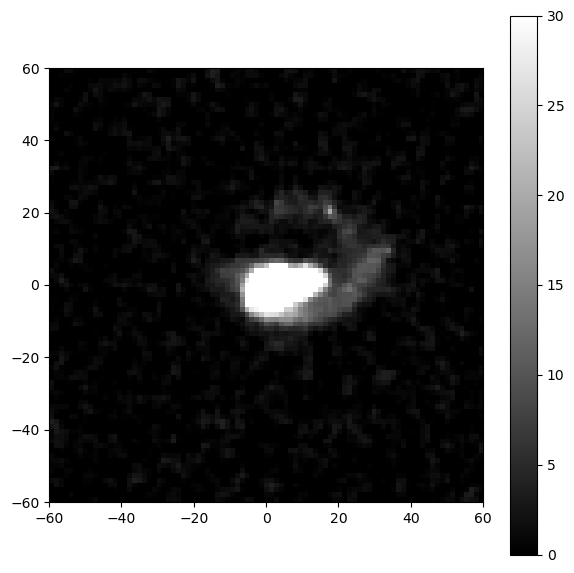

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=58.6_a=287.4_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


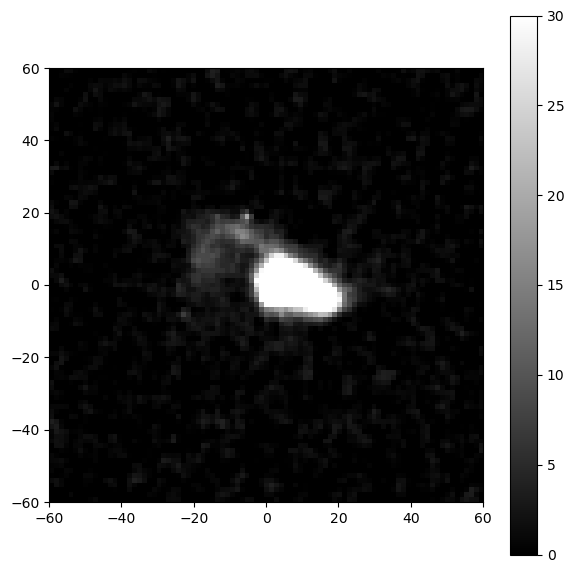

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=61.4_a=149.9_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


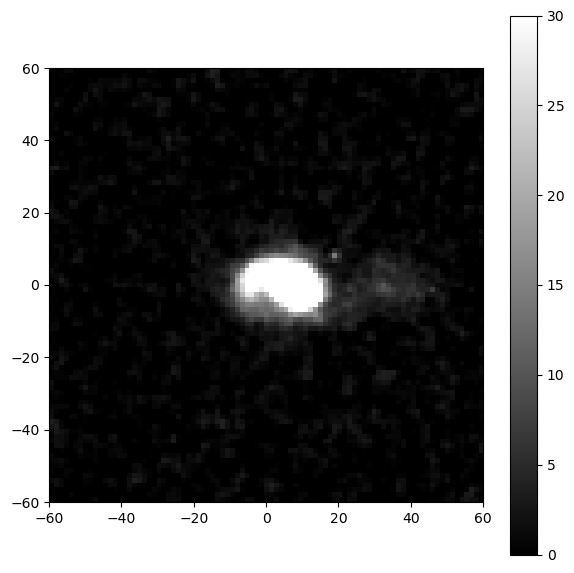

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=64.2_a=12.4_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


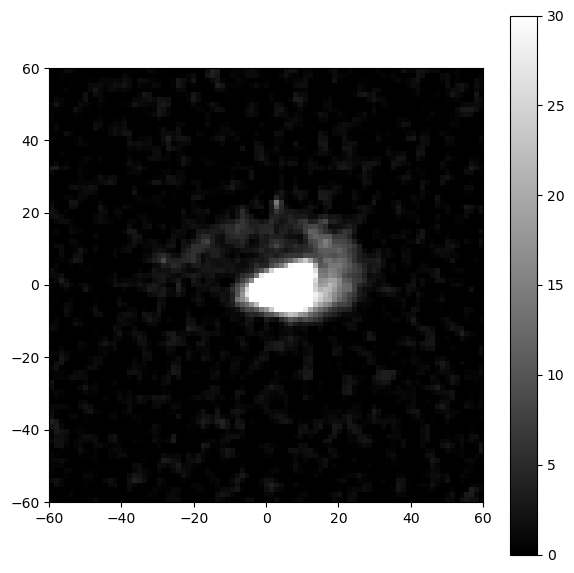

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=67.0_a=234.9_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


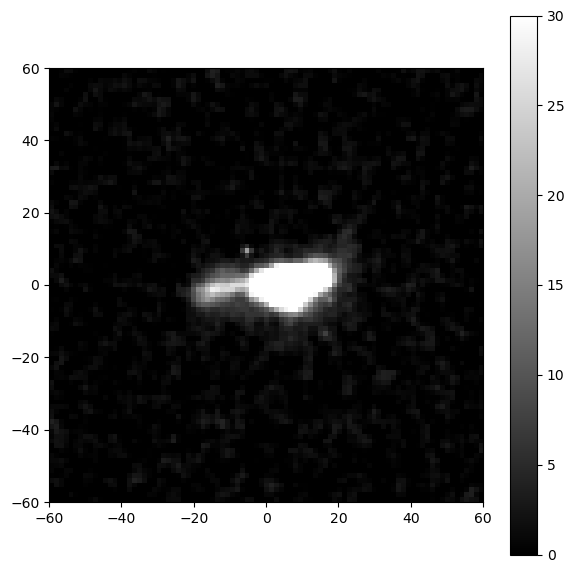

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=69.6_a=97.4_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


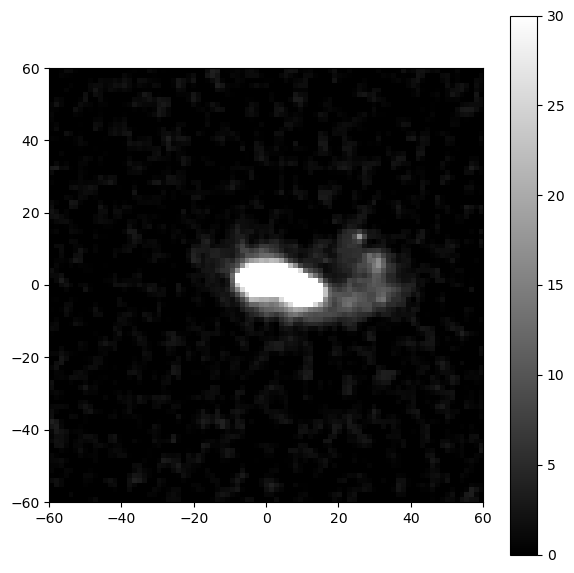

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=72.3_a=319.9_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


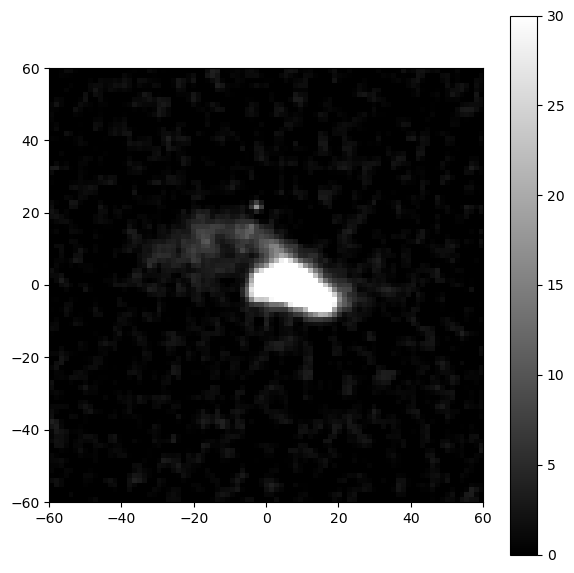

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=74.9_a=182.4_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


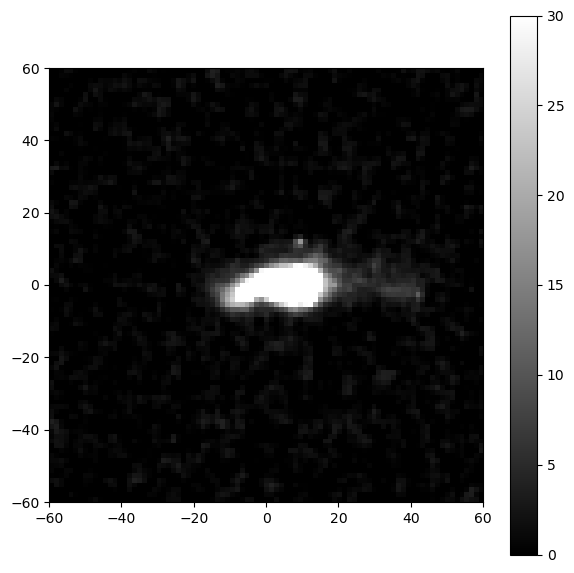

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=77.4_a=44.9_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


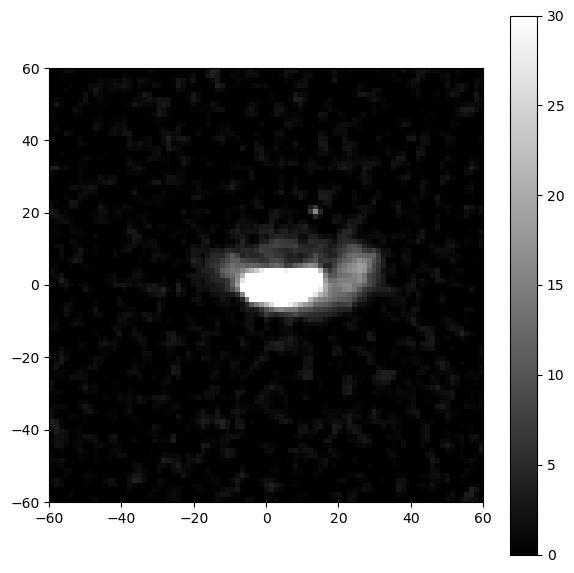

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=80.0_a=267.4_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


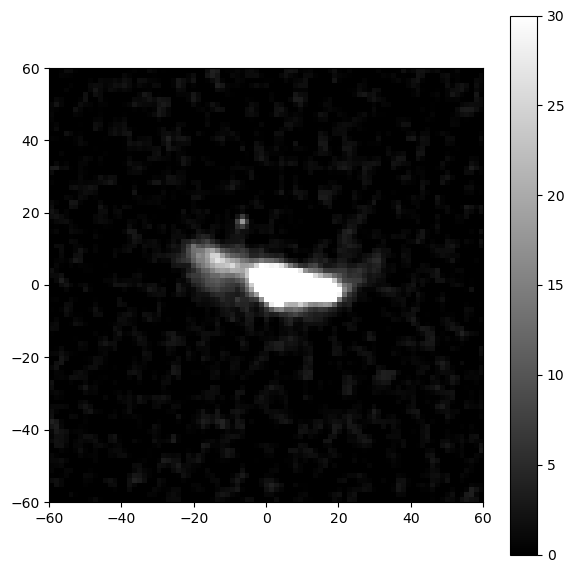

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=82.5_a=129.8_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


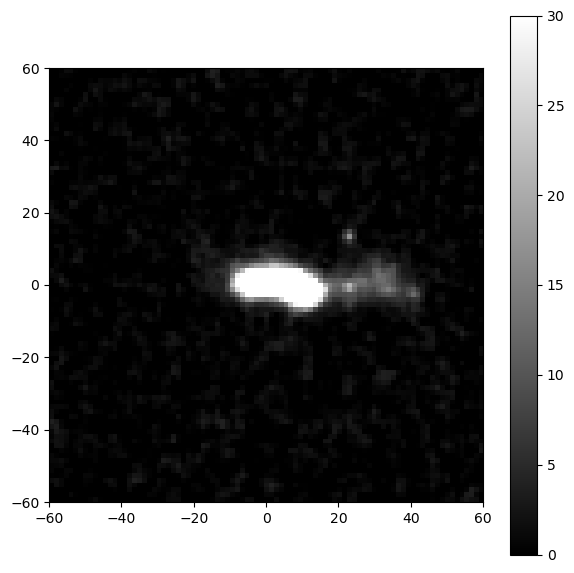

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=85.0_a=352.3_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


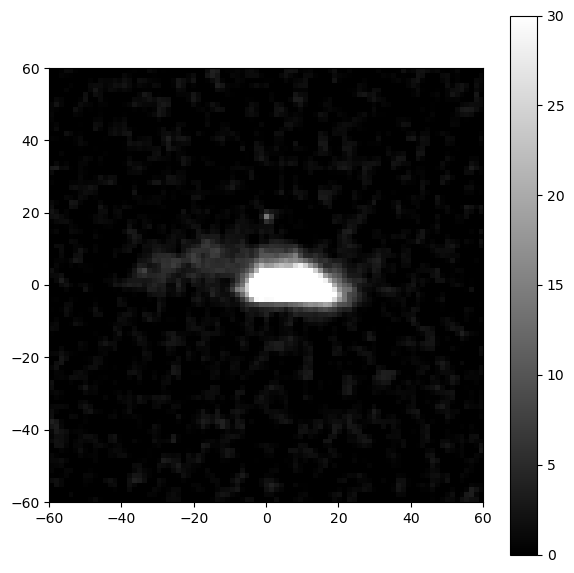

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=87.5_a=214.8_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


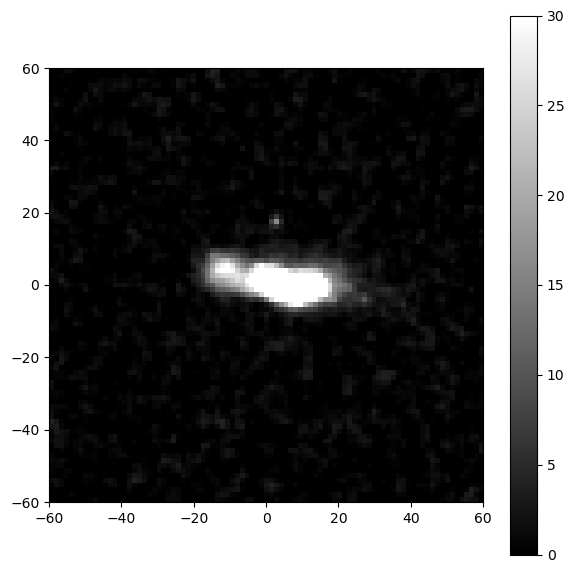

Filename: ../matched_filter/mf_data/mf_catalogs/26p5_2000/storm_2/mf_storm_2_d=90.0_a=77.3_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       7   (89, 89)   float64   


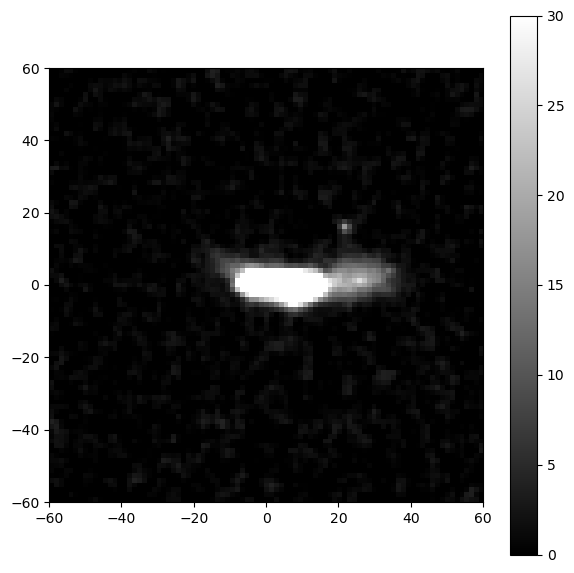

In [17]:
# display the matched-filter outputs
for file in sorted(mf_catalogs_path.iterdir()):
    if file.is_file():

        my_extent = [-60,60,-60,60]
        
        # pure
        hdul = fits.open(f'{mf_catalogs_path}/{file.name}')
        hdul.info()
        image_data = np.squeeze(hdul[0].data)
        plt.figure(figsize=(7,7))
        plt.imshow(image_data, extent=my_extent, \
                    cmap = 'gray', vmin = 0, vmax = 30, origin='lower')
        plt.colorbar()
        plt.show()
        hdul.close()

        # contoured
        # hdul = fits.open(f'{mf_catalogs_path}/{file.name}')
        # hdul.info()
        # image_data = np.squeeze(hdul[0].data)
        # x_coords = np.linspace(my_extent[0], my_extent[1], image_data.shape[1])
        # y_coords = np.linspace(my_extent[2], my_extent[3], image_data.shape[0])
        # X, Y = np.meshgrid(x_coords, y_coords)
        # plt.figure(figsize=(7,7))
        # plt.imshow(image_data, extent=my_extent, \
        #             cmap = 'gray', vmin = 0, vmax = 30, origin='lower')
        # plt.colorbar()
        # median = np.median(image_data)
        # mad = np.median(np.abs(image_data - median))
        # sigma = mad * 1.4826
        # smoothed_data = gaussian_filter(image_data, sigma=1.2)
        # plt.contour(X, Y, smoothed_data, extent=[-60,60,-60,60], colors='white', \
        #             levels=[1 * sigma, 1.5 * sigma, 2 * sigma, 2.5 * sigma, 5 * sigma, 10 * sigma, 35 * sigma], \
        #             linewidths=1.0, origin='lower')
        # plt.show()
        # hdul.close()

In [18]:
# load the 2D exponential fit outputs path
twod_exp_fit_path = path(f'../substructure_detection/sd_outputs/twod_exp_fit/{galaxy_name}/reduced')

storm_2_reduced_d=0.0_a=0.0_pix=8000.png


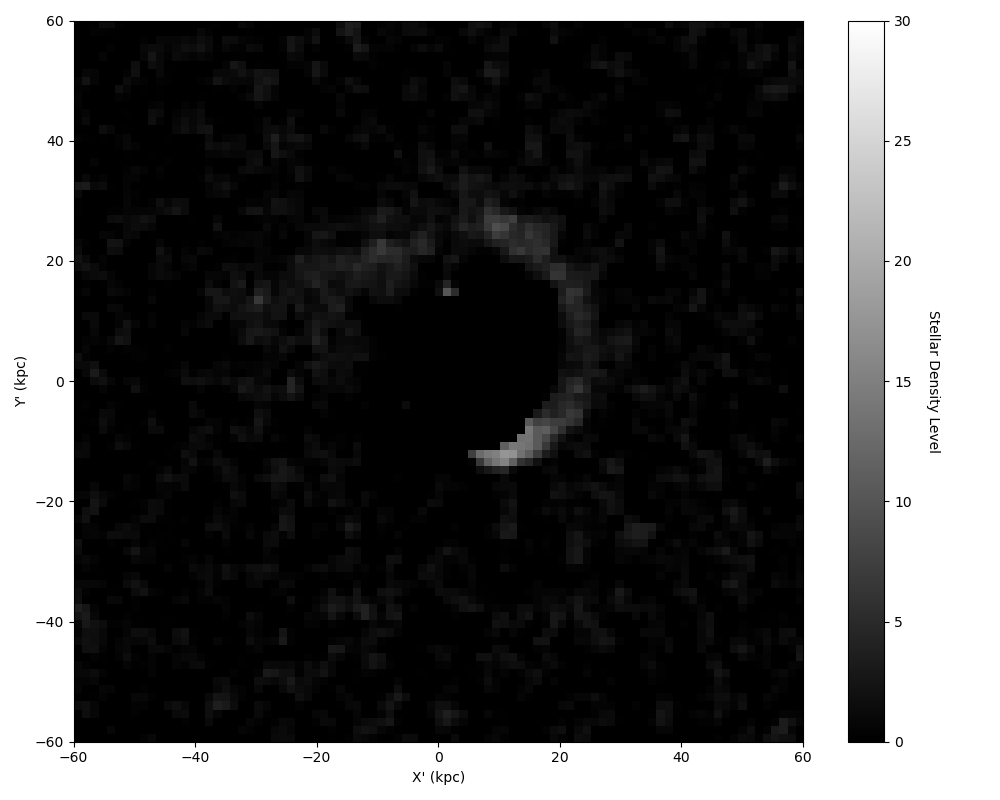

storm_2_reduced_d=17.0_a=222.5_pix=8000.png


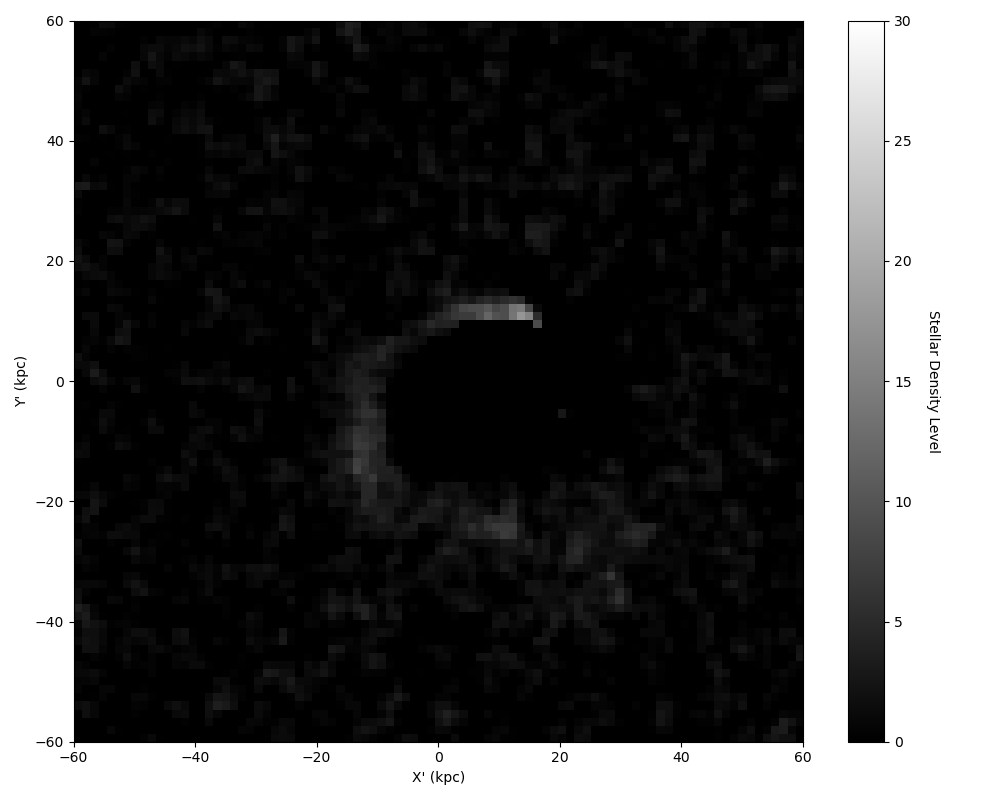

storm_2_reduced_d=24.1_a=85.0_pix=8000.png


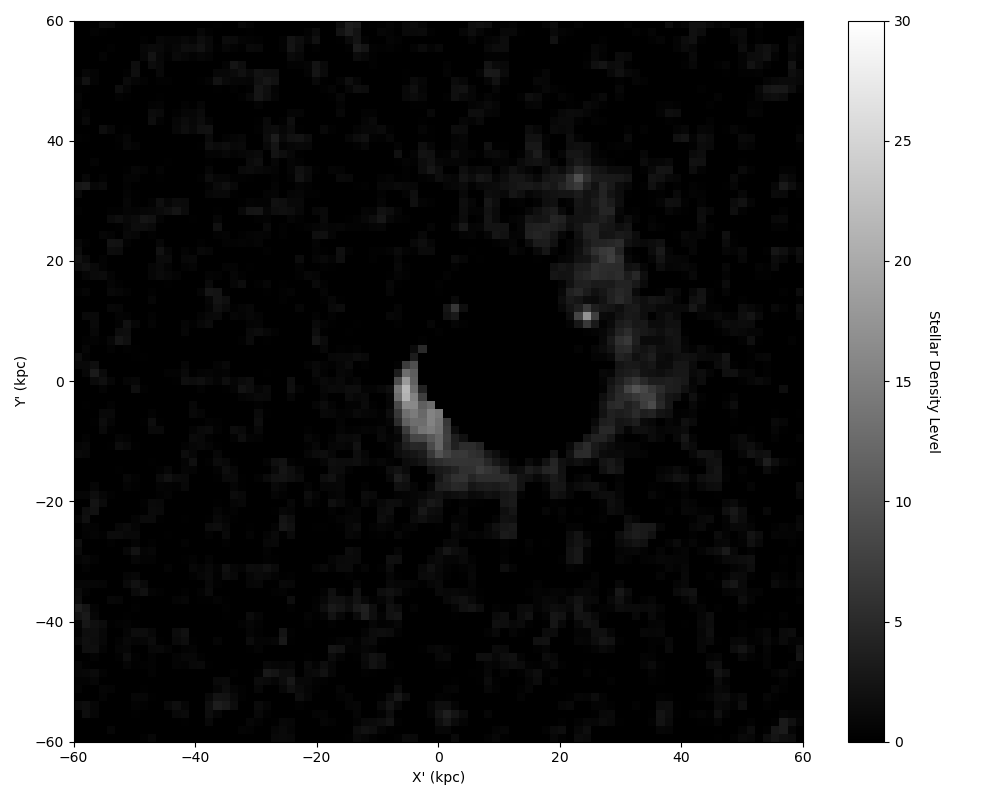

storm_2_reduced_d=29.6_a=307.5_pix=8000.png


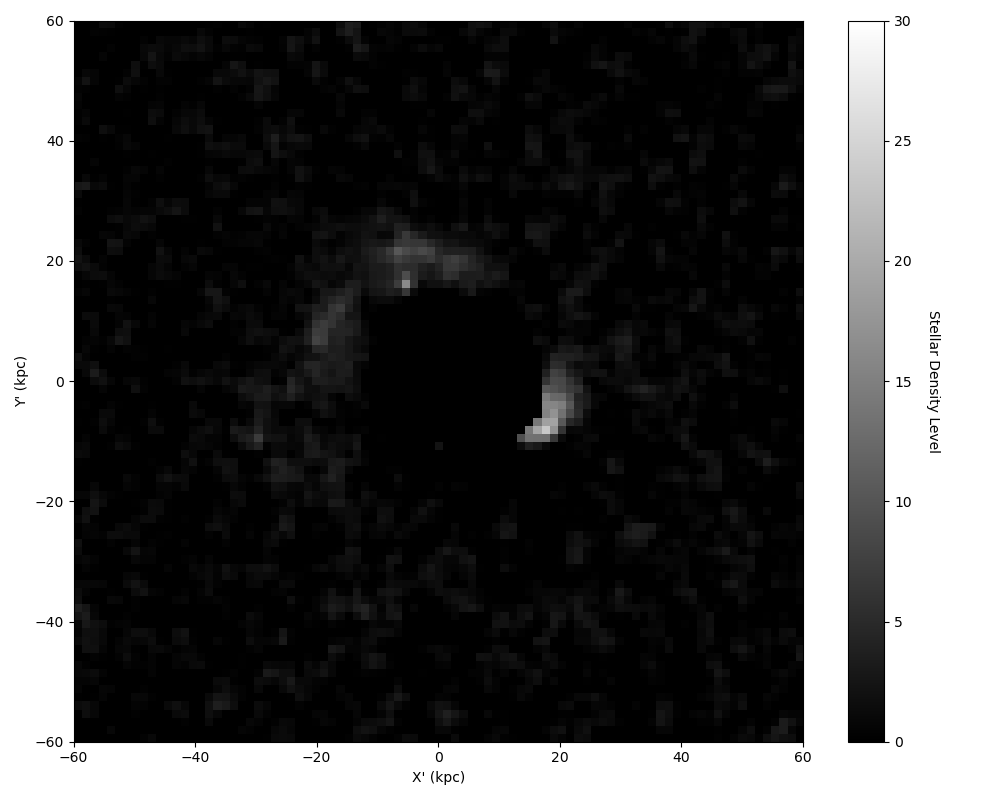

storm_2_reduced_d=34.3_a=170.0_pix=8000.png


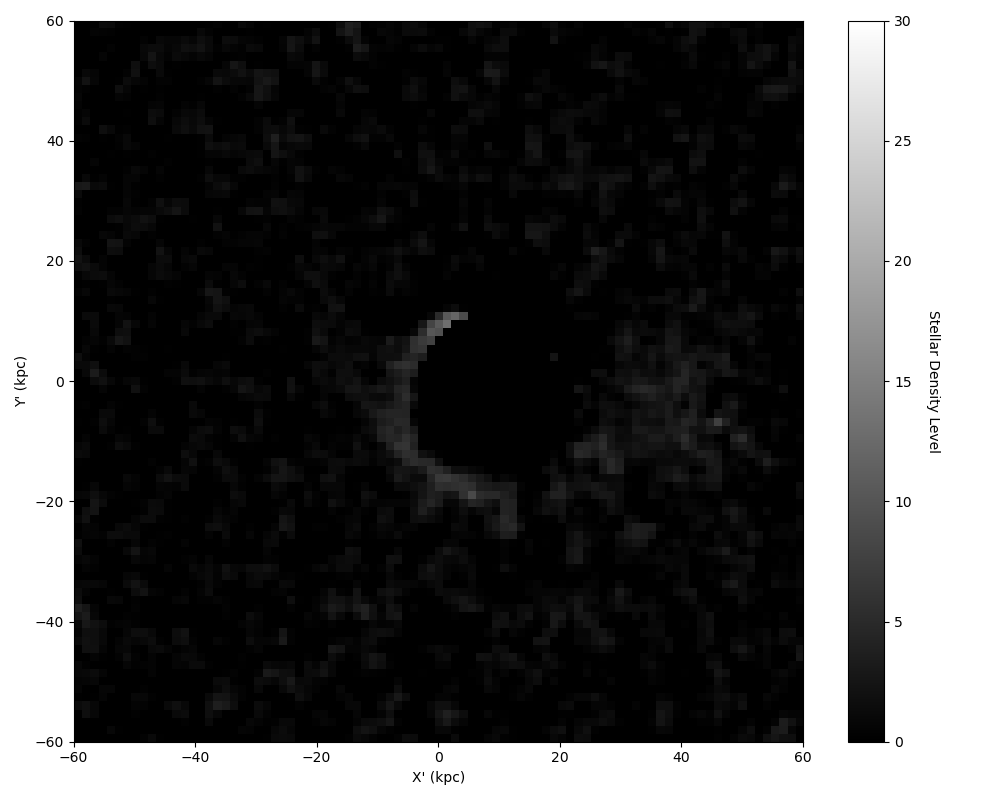

storm_2_reduced_d=38.5_a=32.5_pix=8000.png


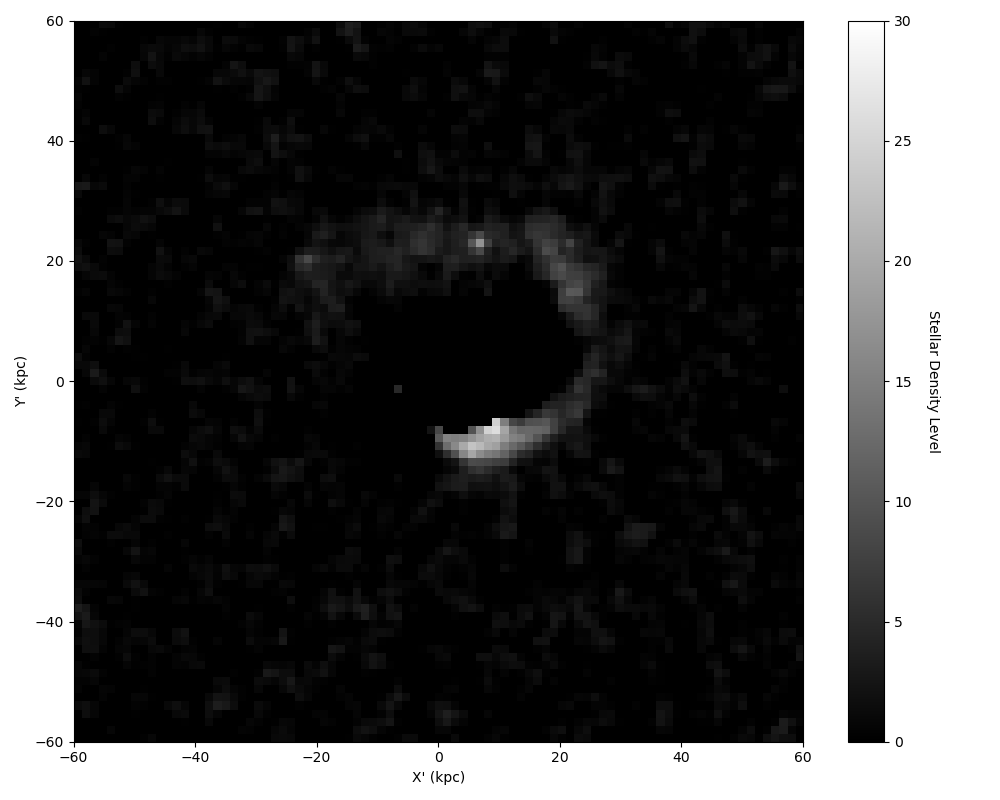

storm_2_reduced_d=42.3_a=255.0_pix=8000.png


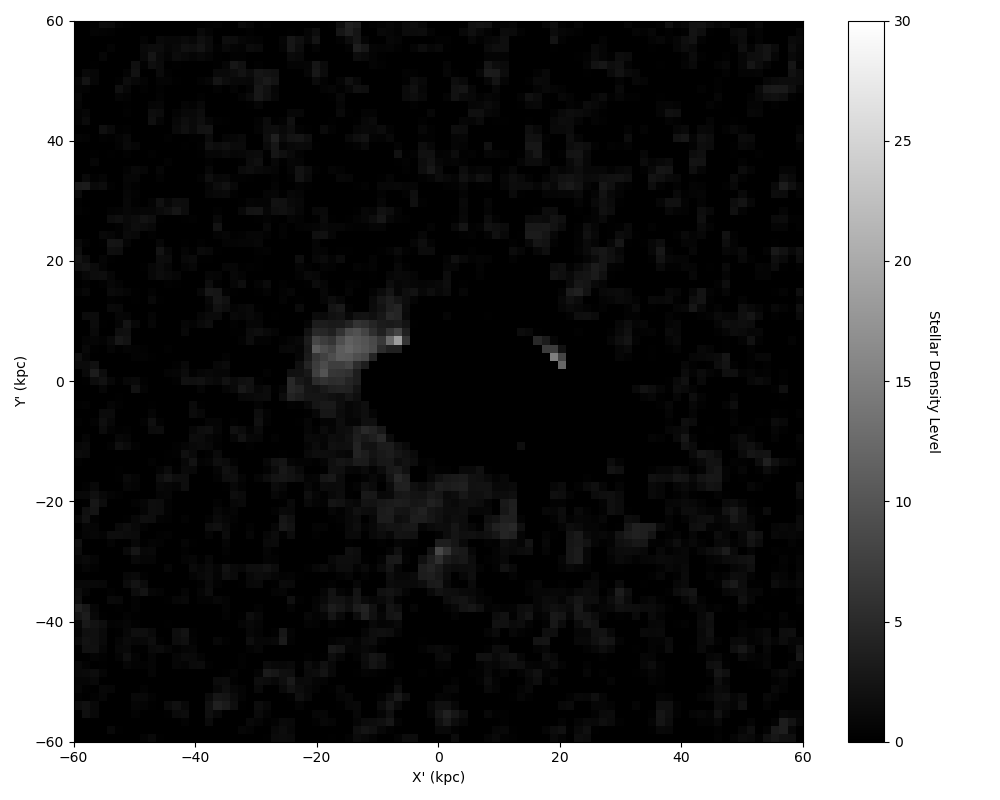

storm_2_reduced_d=45.9_a=117.4_pix=8000.png


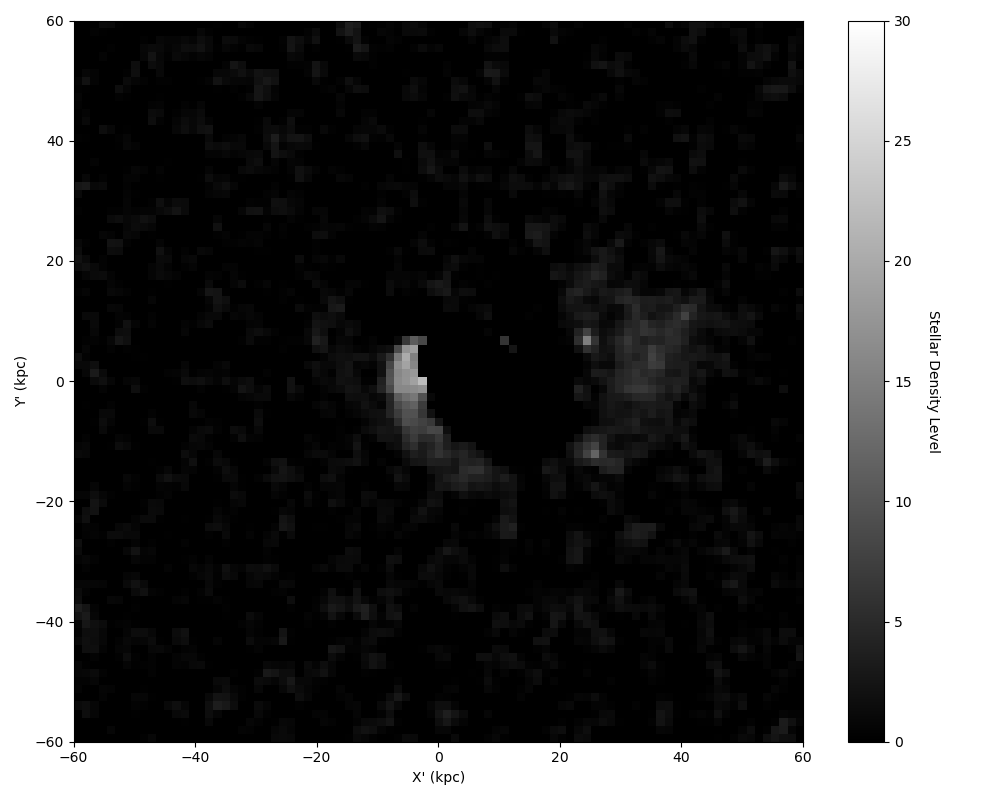

storm_2_reduced_d=49.3_a=339.9_pix=8000.png


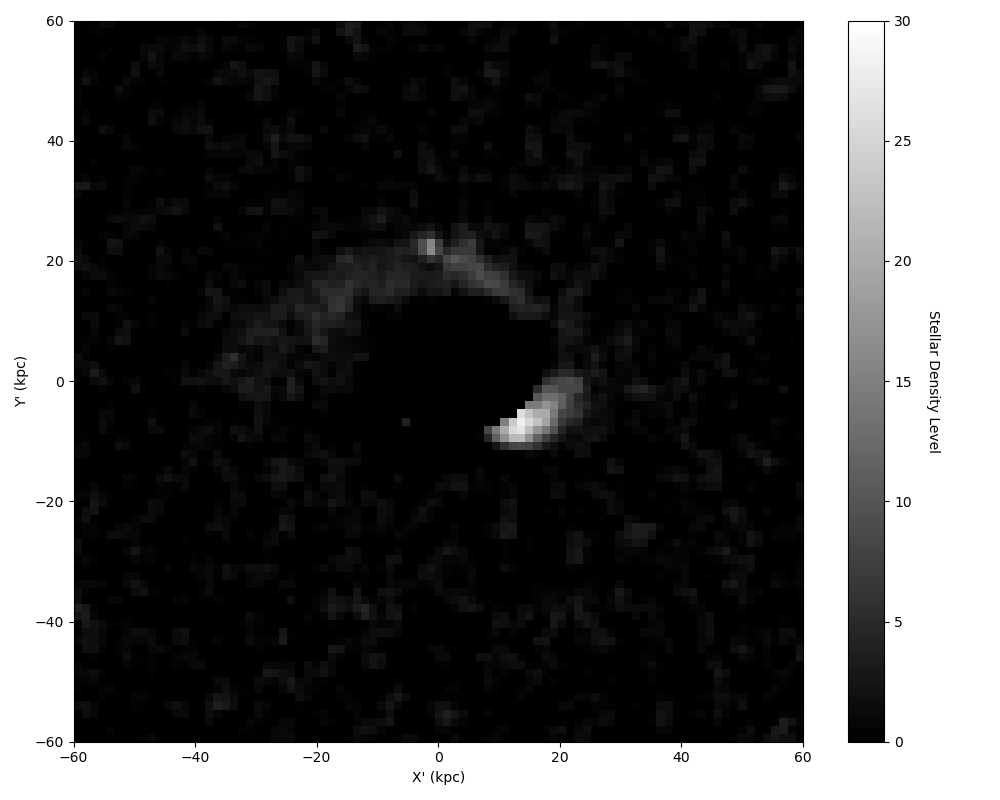

storm_2_reduced_d=52.5_a=202.4_pix=8000.png


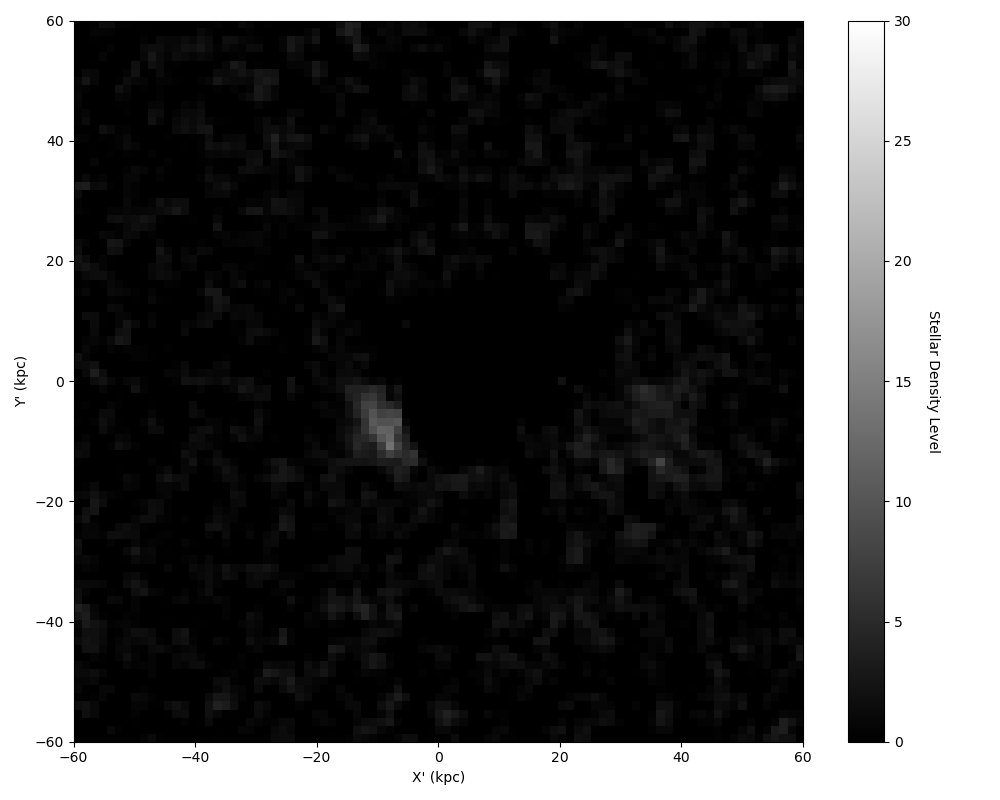

storm_2_reduced_d=55.6_a=64.9_pix=8000.png


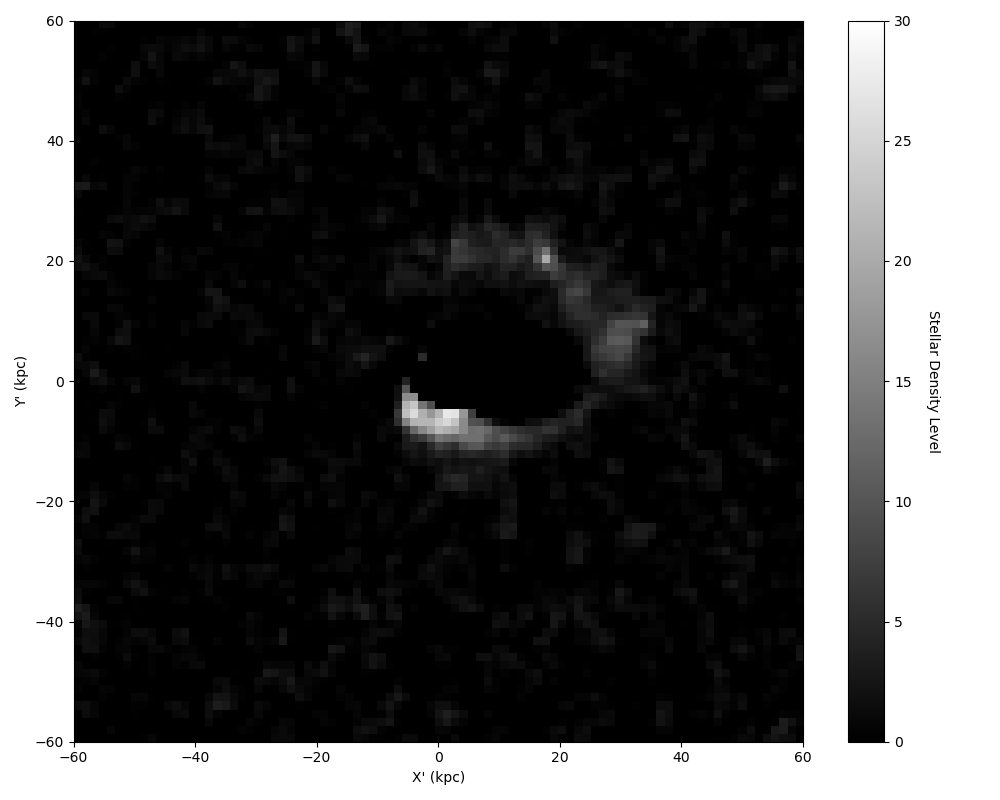

storm_2_reduced_d=58.6_a=287.4_pix=8000.png


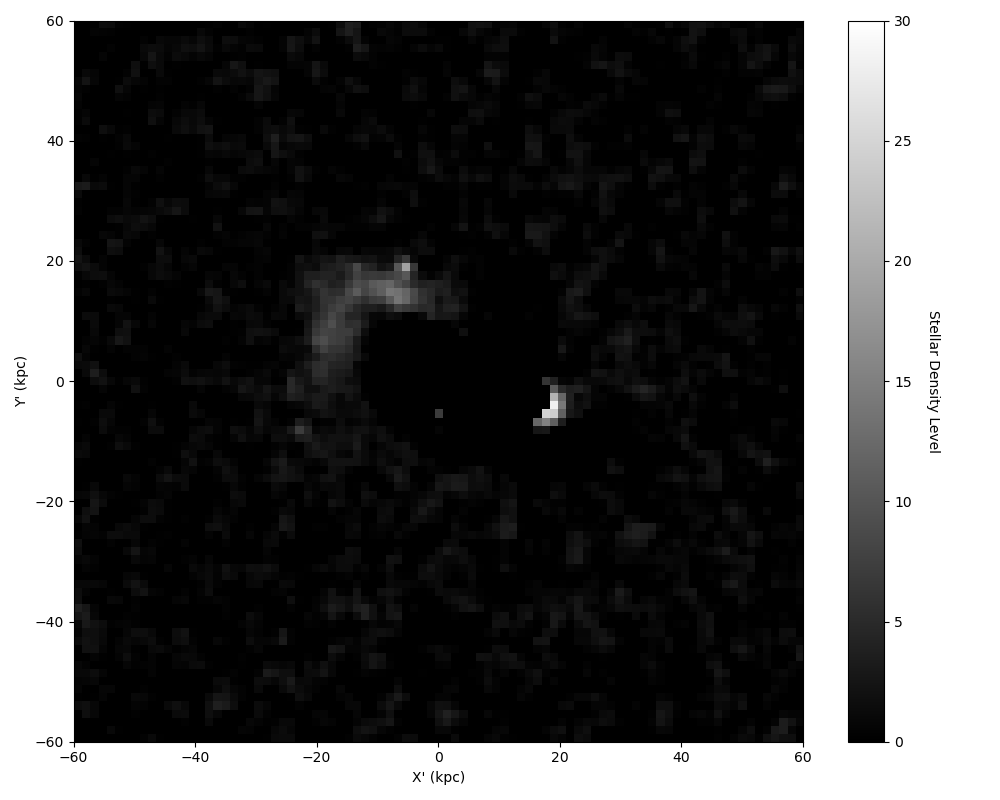

storm_2_reduced_d=61.4_a=149.9_pix=8000.png


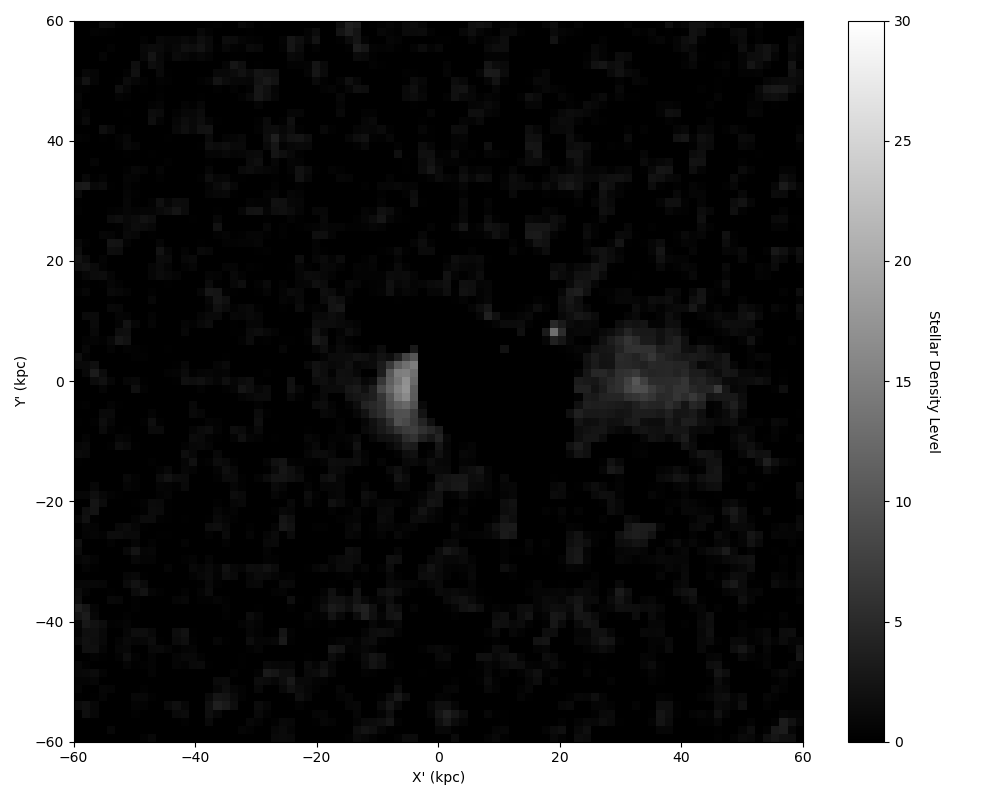

storm_2_reduced_d=64.2_a=12.4_pix=8000.png


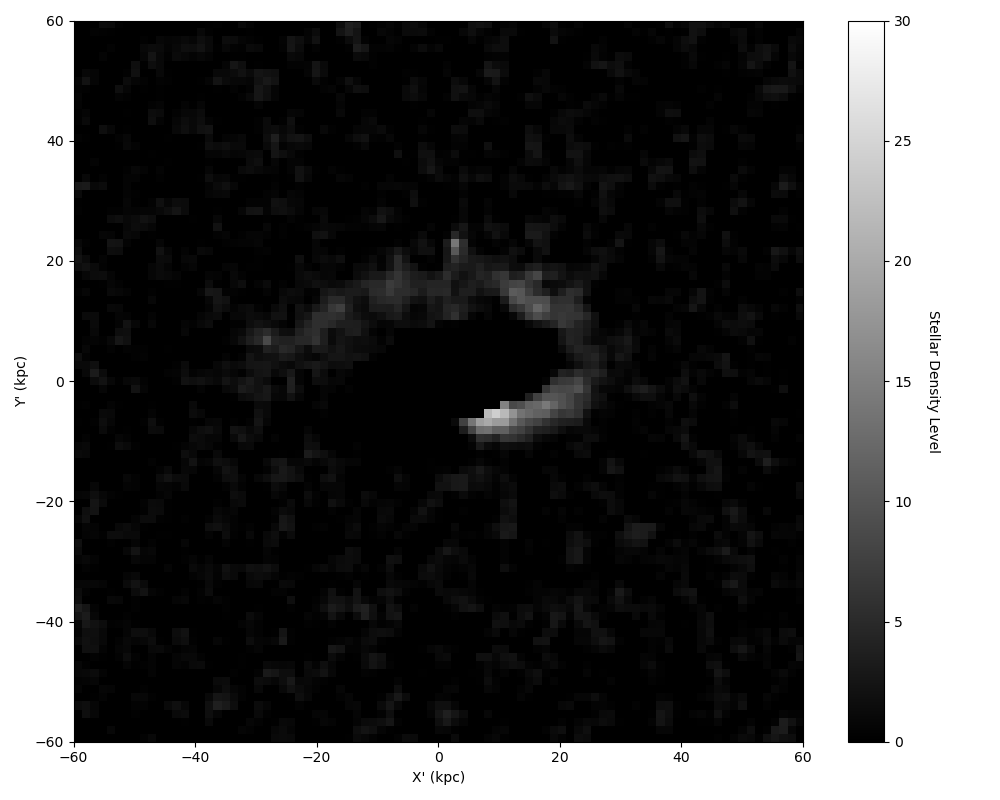

storm_2_reduced_d=67.0_a=234.9_pix=8000.png


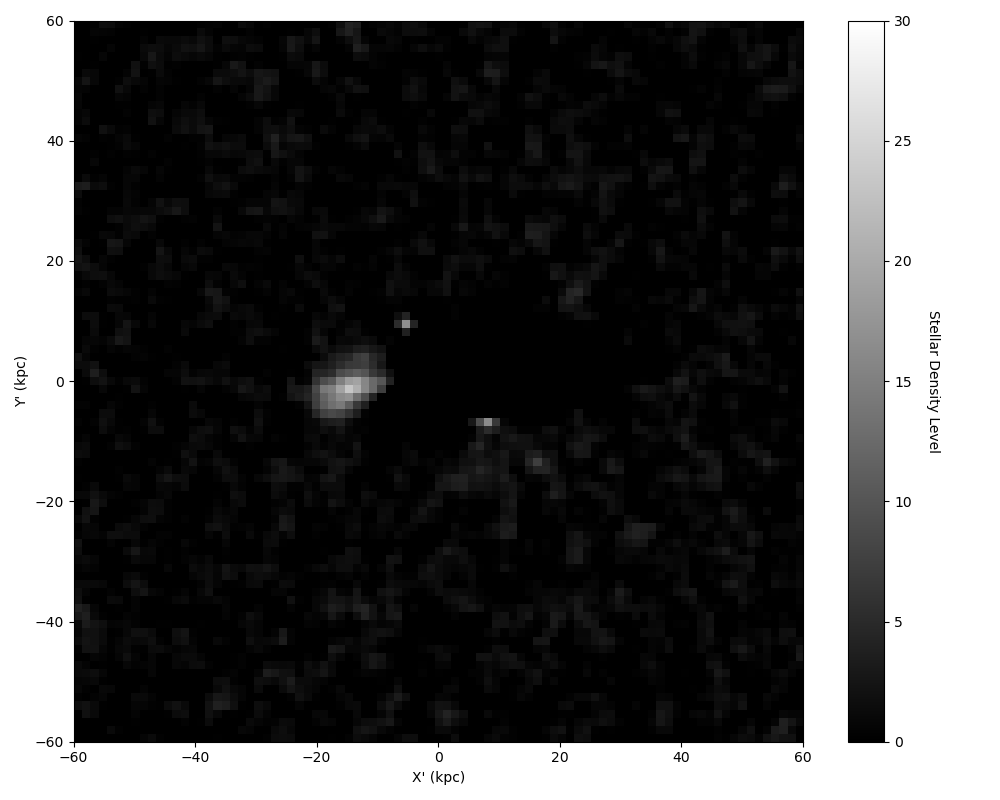

storm_2_reduced_d=69.6_a=97.4_pix=8000.png


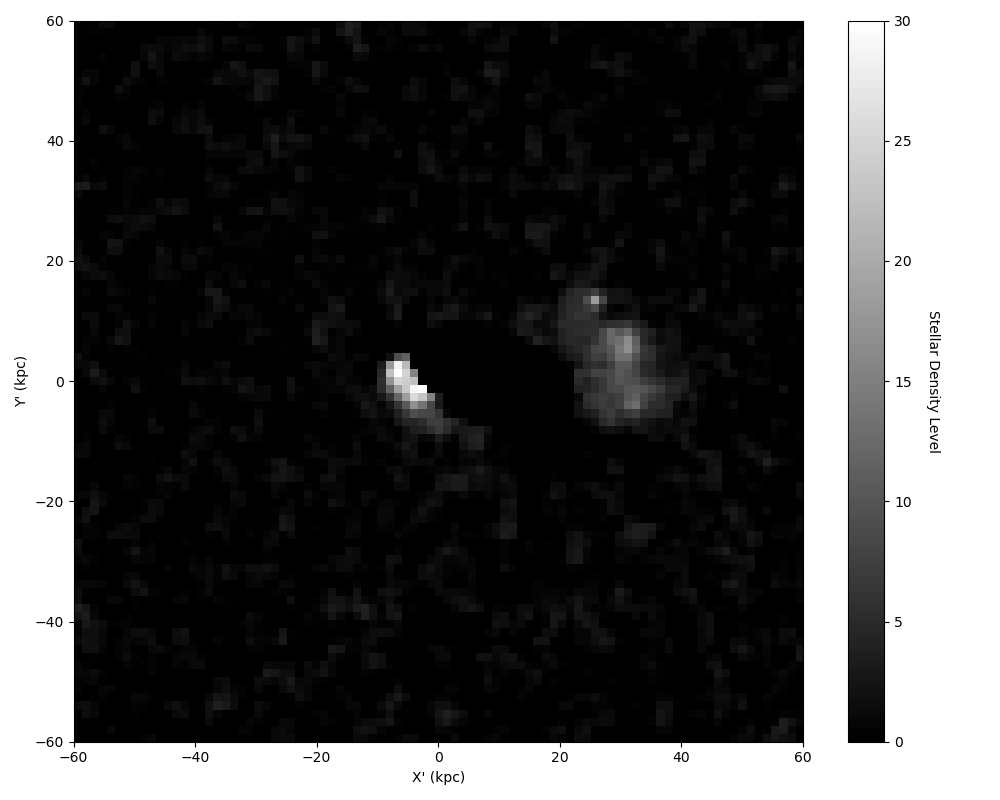

storm_2_reduced_d=72.3_a=319.9_pix=8000.png


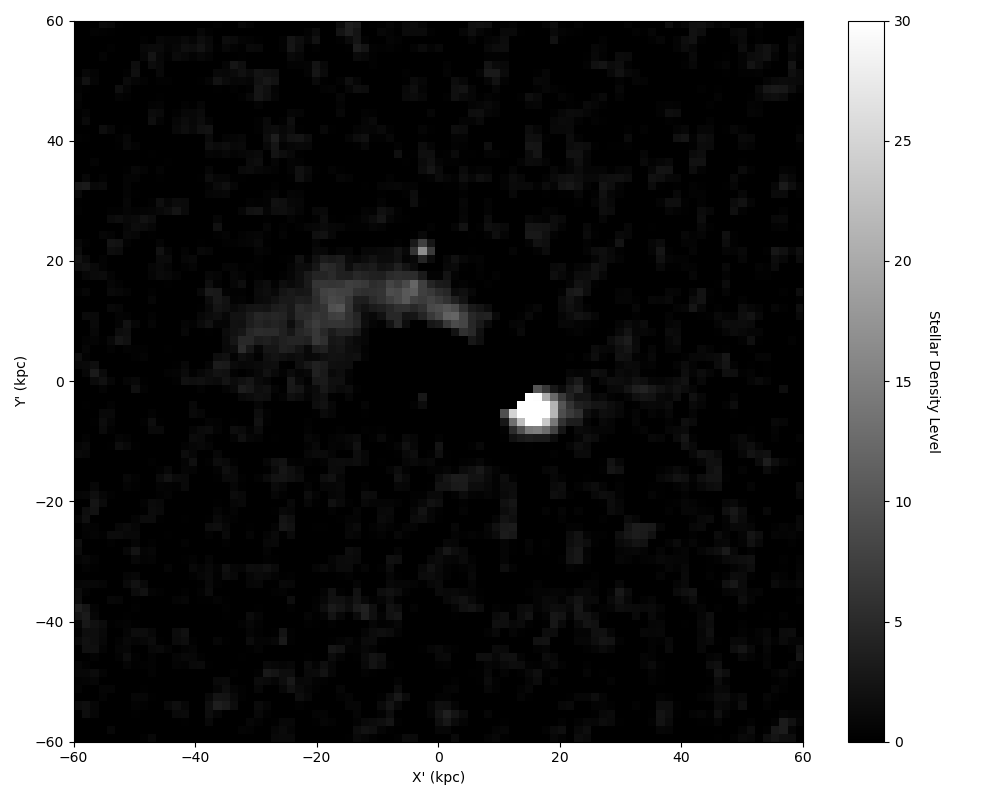

storm_2_reduced_d=74.9_a=182.4_pix=8000.png


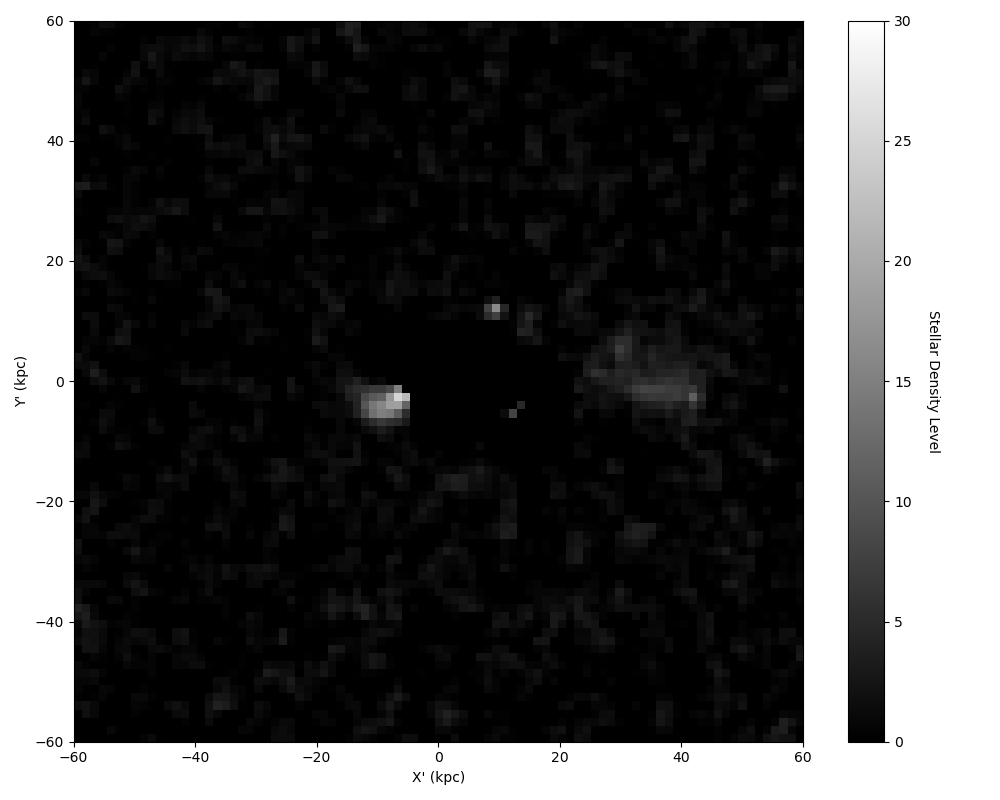

storm_2_reduced_d=77.4_a=44.9_pix=8000.png


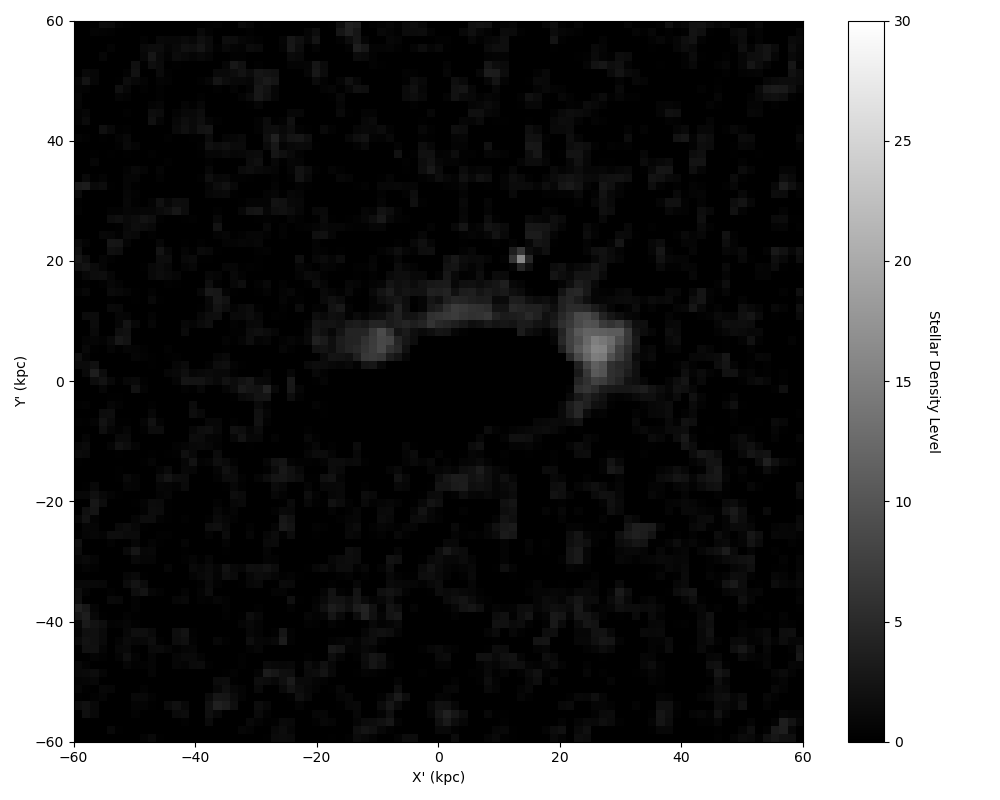

storm_2_reduced_d=80.0_a=267.4_pix=8000.png


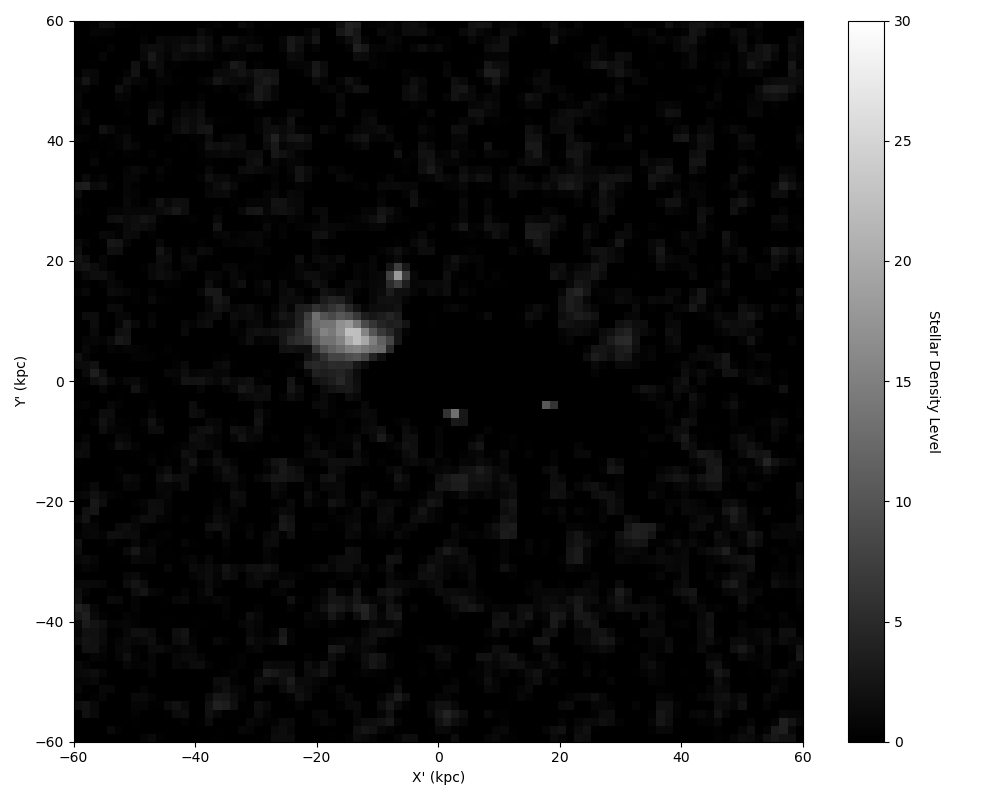

storm_2_reduced_d=82.5_a=129.8_pix=8000.png


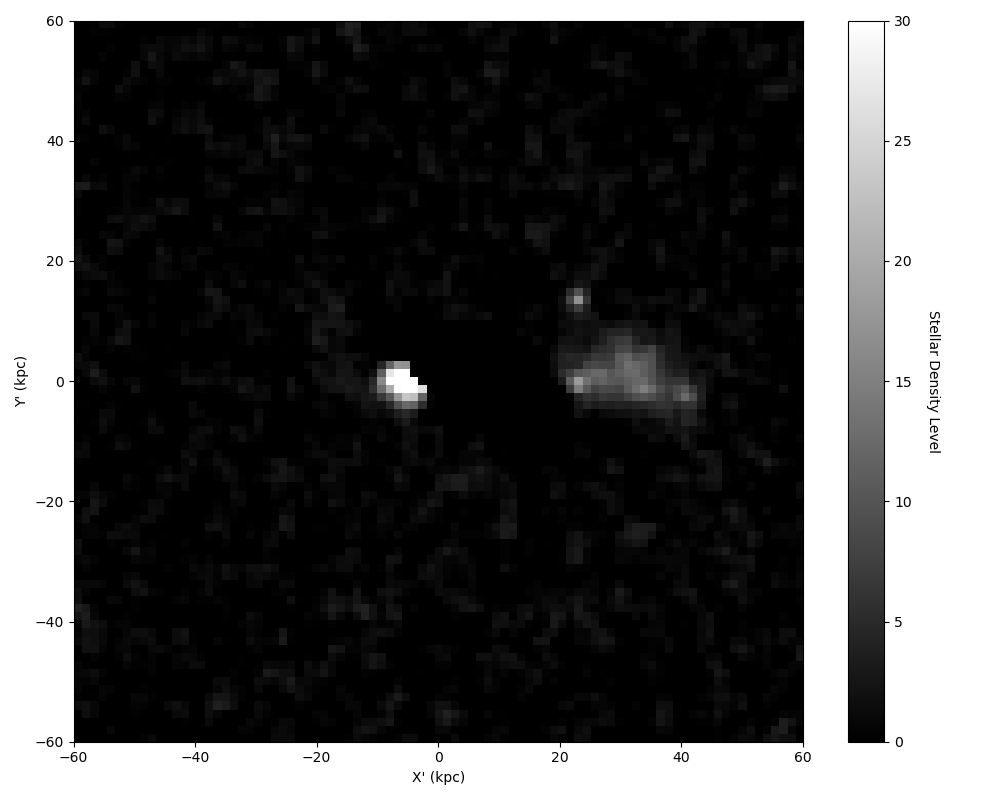

storm_2_reduced_d=85.0_a=352.3_pix=8000.png


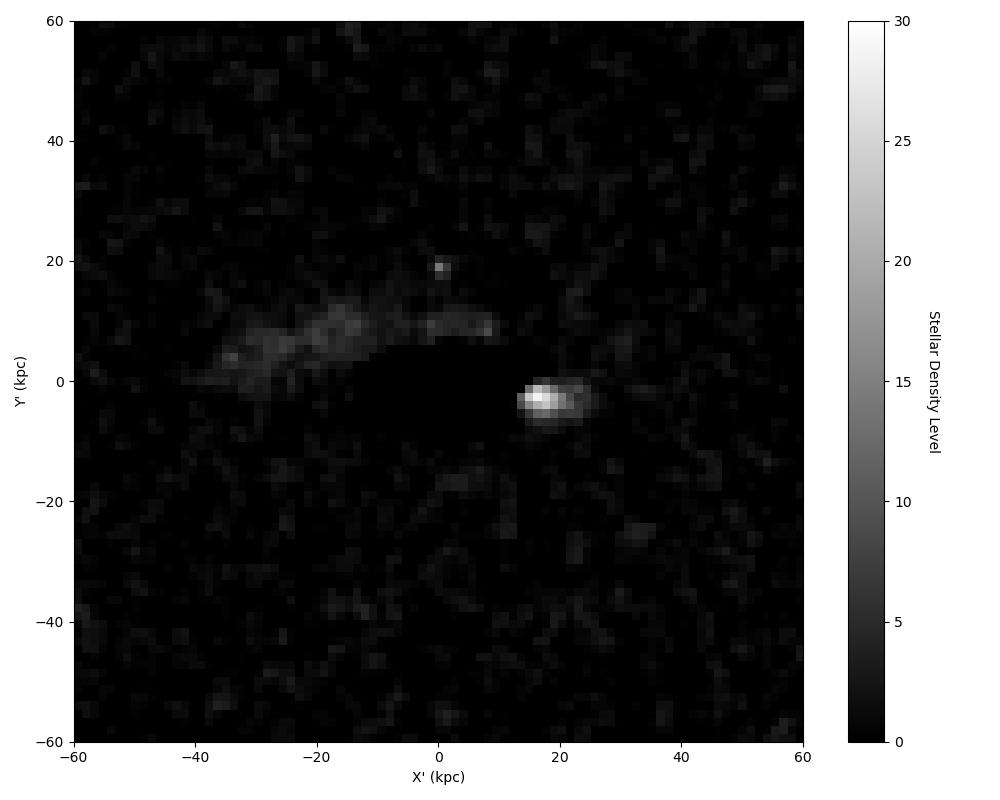

storm_2_reduced_d=87.5_a=214.8_pix=8000.png


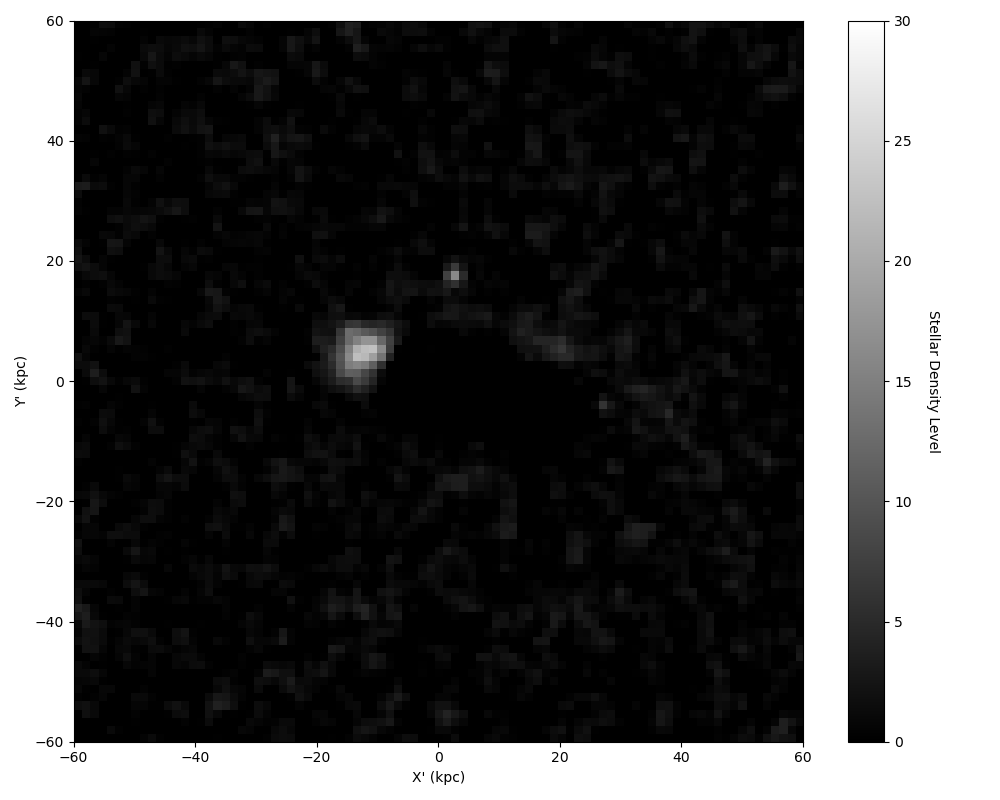

storm_2_reduced_d=90.0_a=77.3_pix=8000.png


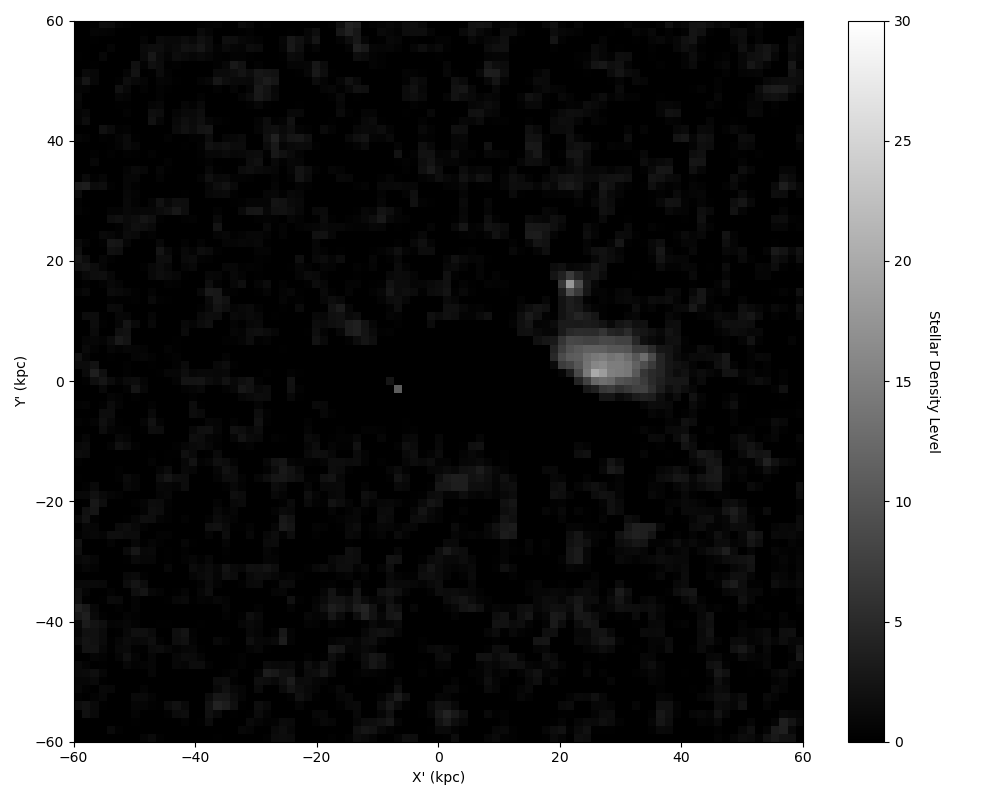

In [19]:
# display the 2D exponential fit outputs
for file in sorted(twod_exp_fit_path.iterdir()):
    if file.is_file():

        print(f'{file.name}')
        
        display(Image(filename=f'{twod_exp_fit_path}/{file.name}'))

In [20]:
# load the Segment outputs path
segmented_path = path(f'../substructure_detection/sd_outputs/Segment/{galaxy_name}/segmented')

segmented_storm_2_d=0.0_a=0.0_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=0.0_a=0.0_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


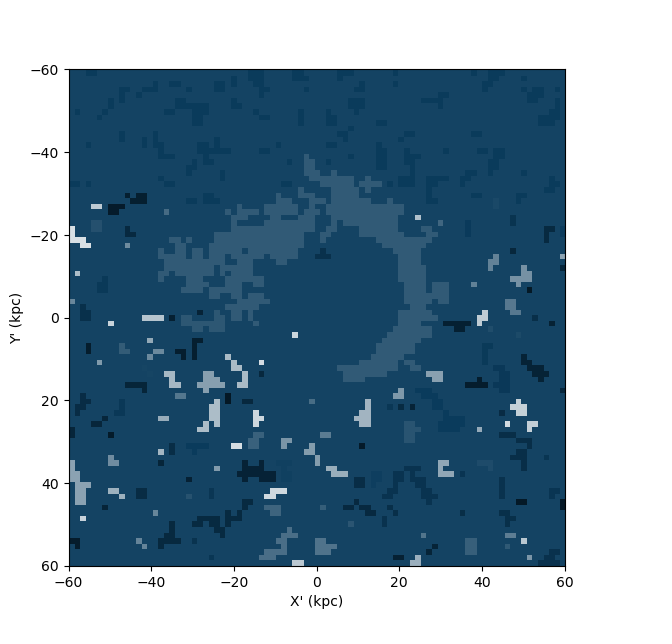

segmented_storm_2_d=17.0_a=222.5_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=17.0_a=222.5_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


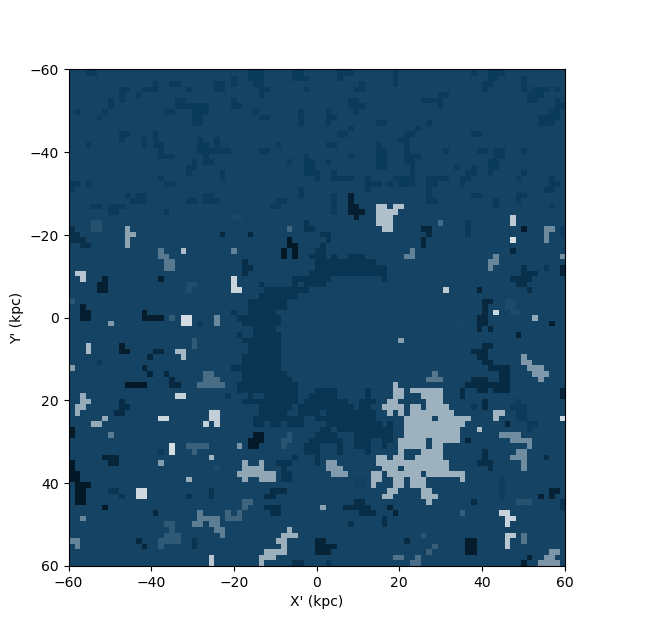

segmented_storm_2_d=24.1_a=85.0_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=24.1_a=85.0_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


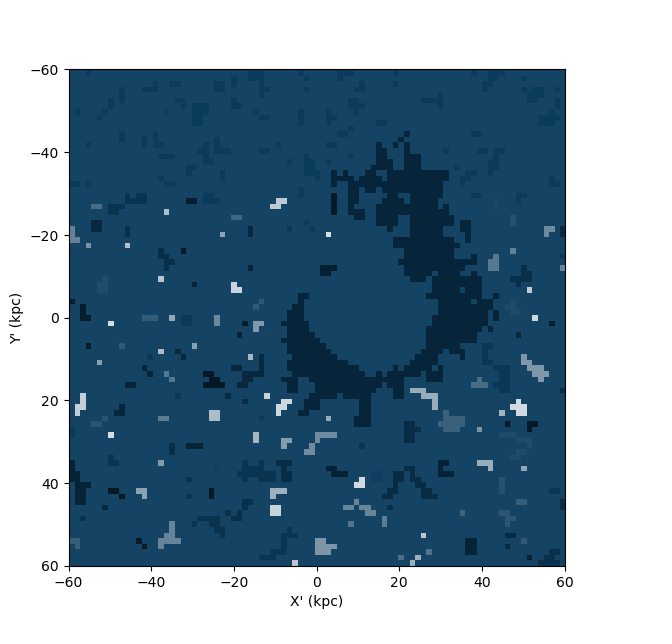

segmented_storm_2_d=29.6_a=307.5_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=29.6_a=307.5_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


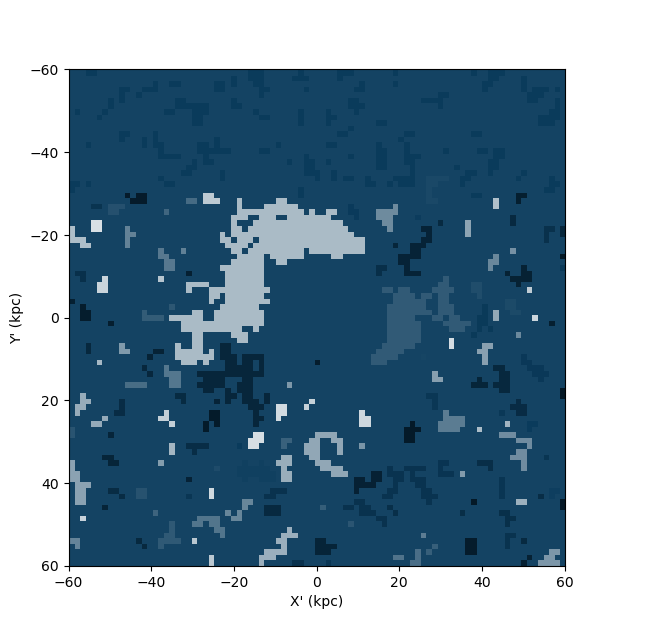

segmented_storm_2_d=34.3_a=170.0_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=34.3_a=170.0_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


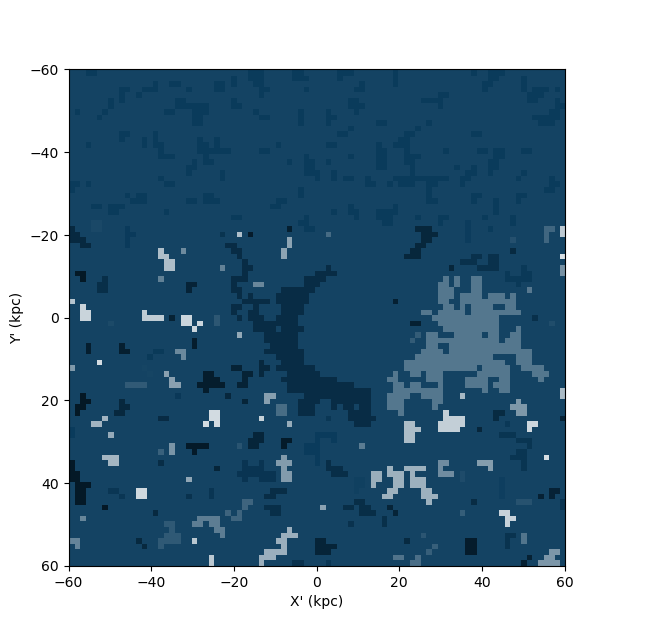

segmented_storm_2_d=38.5_a=32.5_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=38.5_a=32.5_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


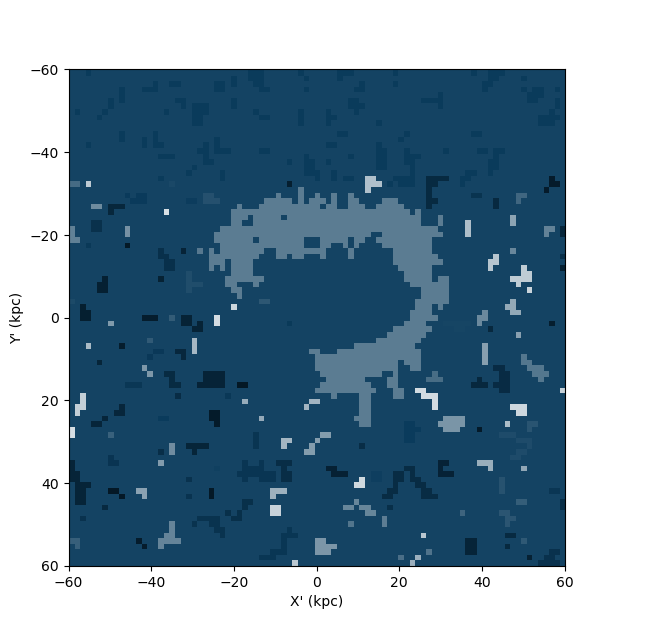

segmented_storm_2_d=42.3_a=255.0_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=42.3_a=255.0_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


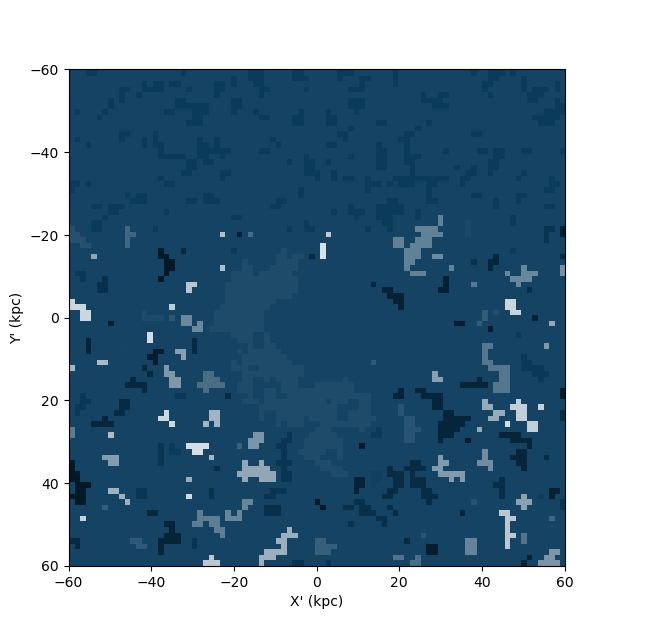

segmented_storm_2_d=45.9_a=117.4_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=45.9_a=117.4_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


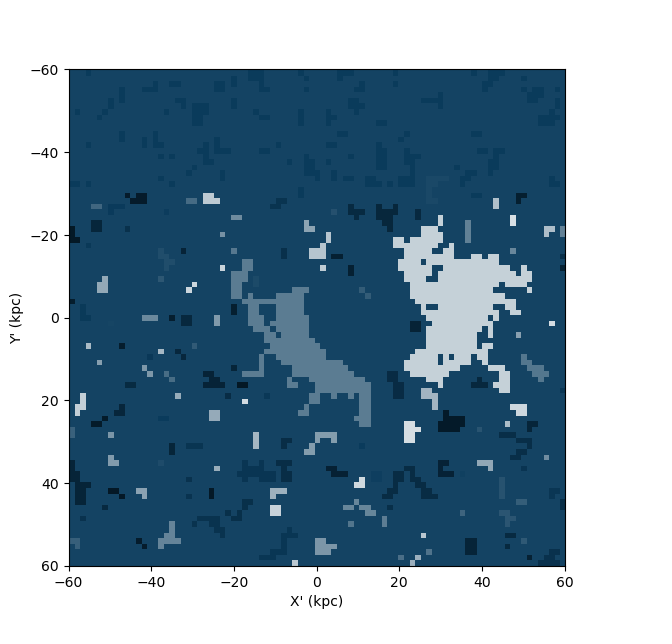

segmented_storm_2_d=49.3_a=339.9_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=49.3_a=339.9_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


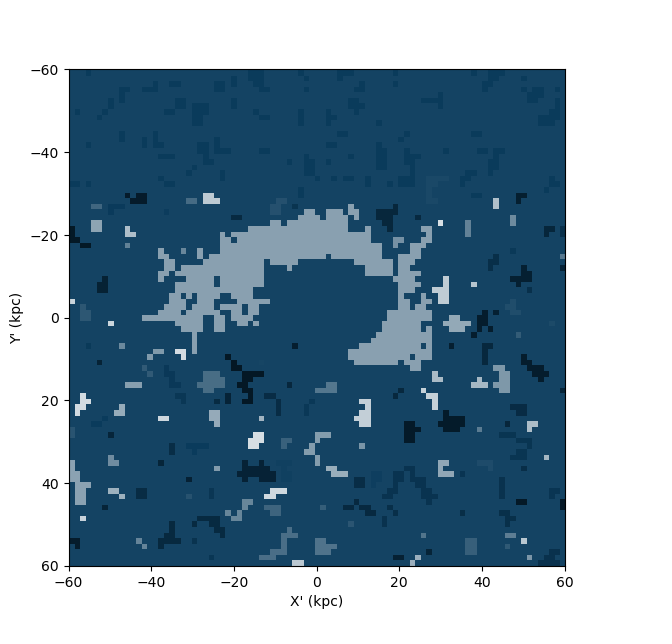

segmented_storm_2_d=52.5_a=202.4_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=52.5_a=202.4_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


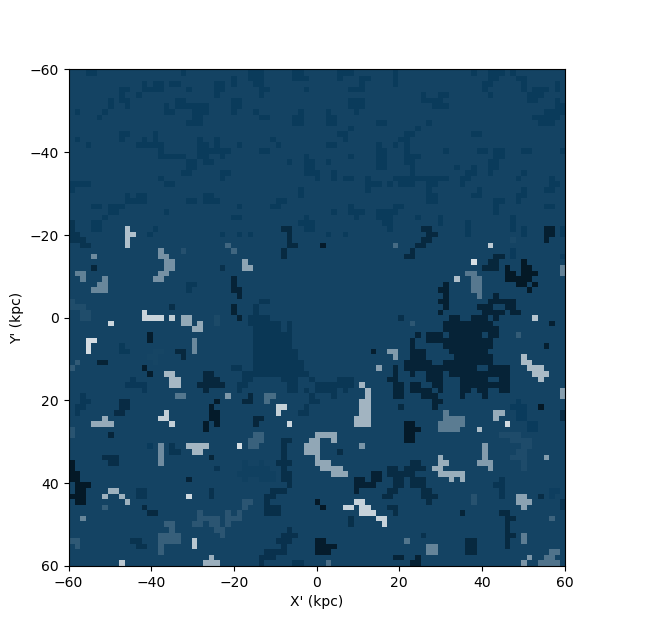

segmented_storm_2_d=55.6_a=64.9_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=55.6_a=64.9_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


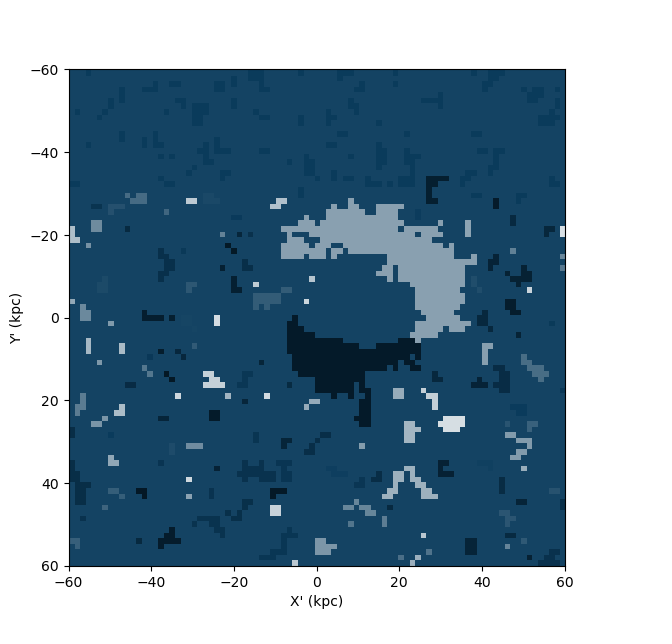

segmented_storm_2_d=58.6_a=287.4_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=58.6_a=287.4_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


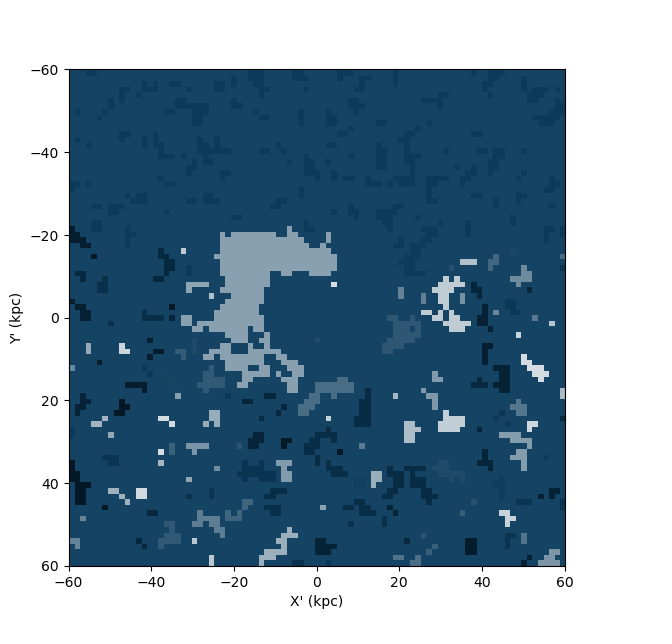

segmented_storm_2_d=61.4_a=149.9_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=61.4_a=149.9_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


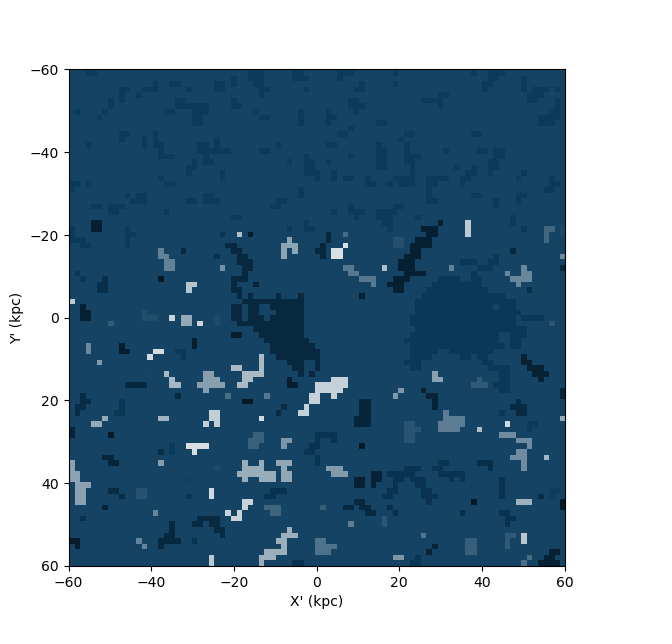

segmented_storm_2_d=64.2_a=12.4_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=64.2_a=12.4_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


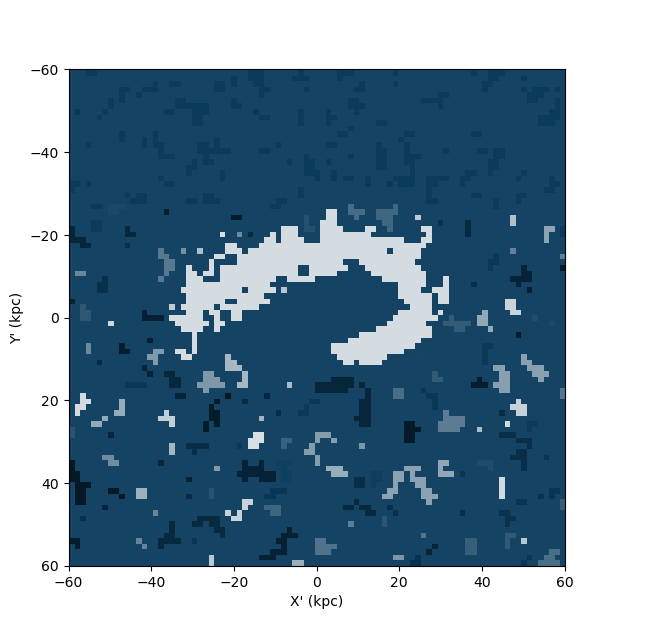

segmented_storm_2_d=67.0_a=234.9_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=67.0_a=234.9_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


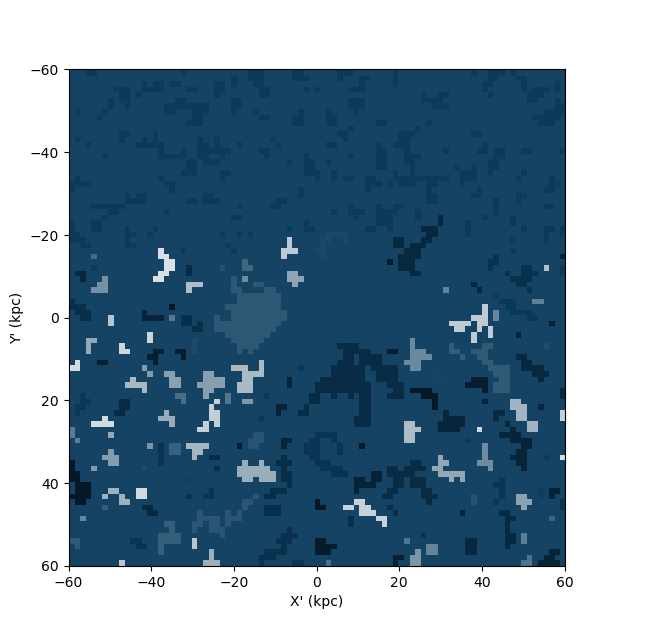

segmented_storm_2_d=69.6_a=97.4_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=69.6_a=97.4_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


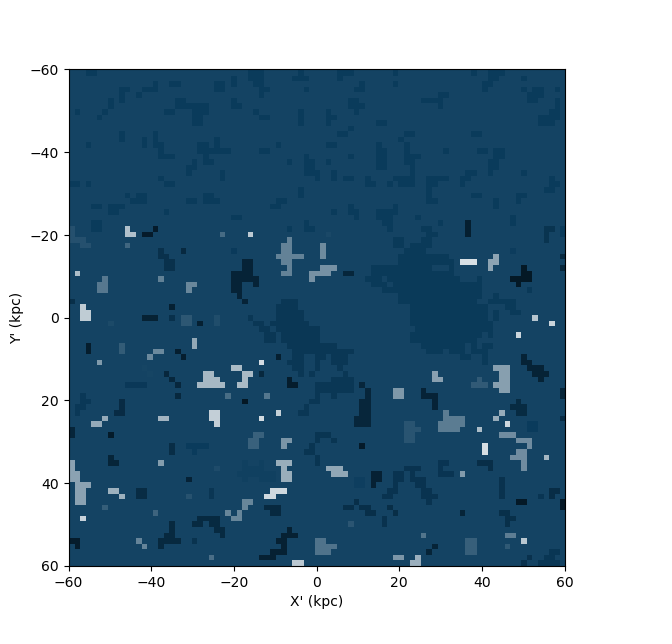

segmented_storm_2_d=72.3_a=319.9_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=72.3_a=319.9_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


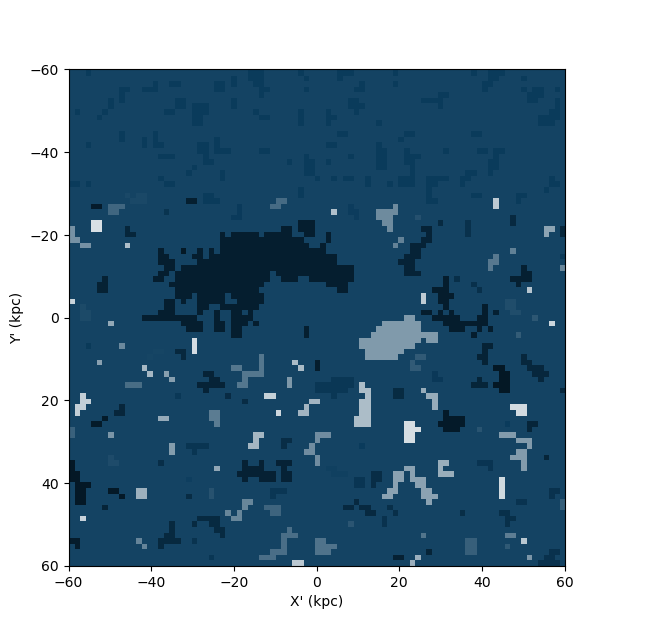

segmented_storm_2_d=74.9_a=182.4_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=74.9_a=182.4_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


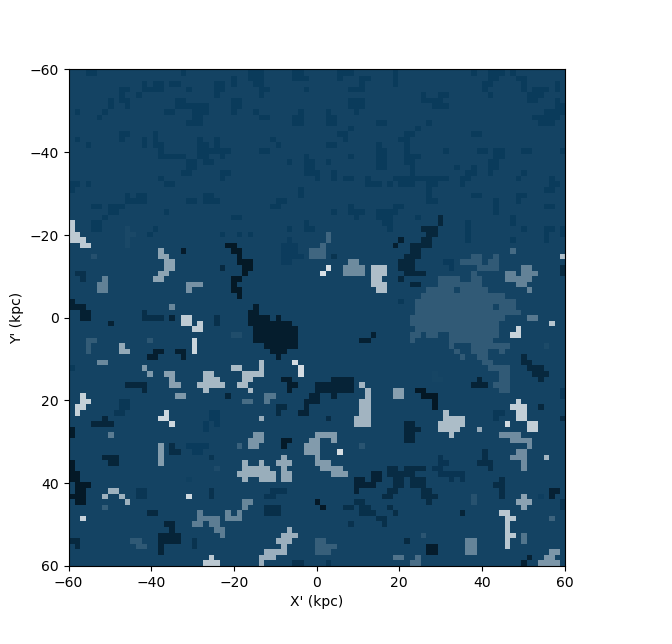

segmented_storm_2_d=77.4_a=44.9_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=77.4_a=44.9_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


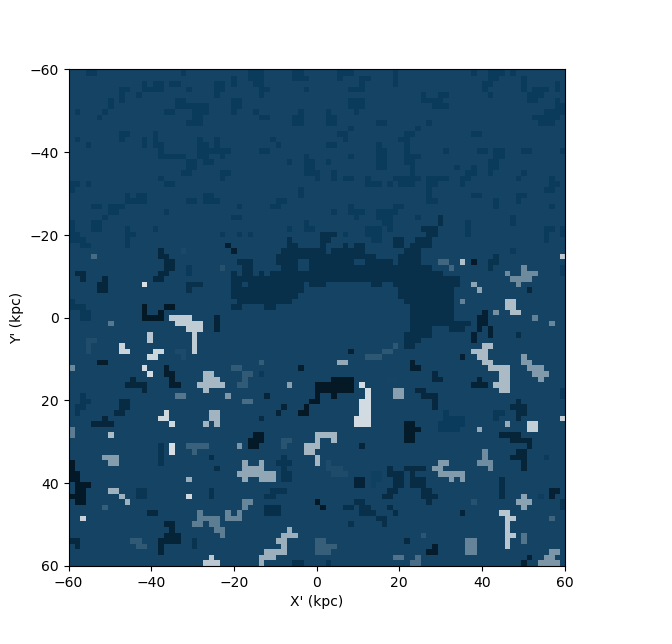

segmented_storm_2_d=80.0_a=267.4_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=80.0_a=267.4_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


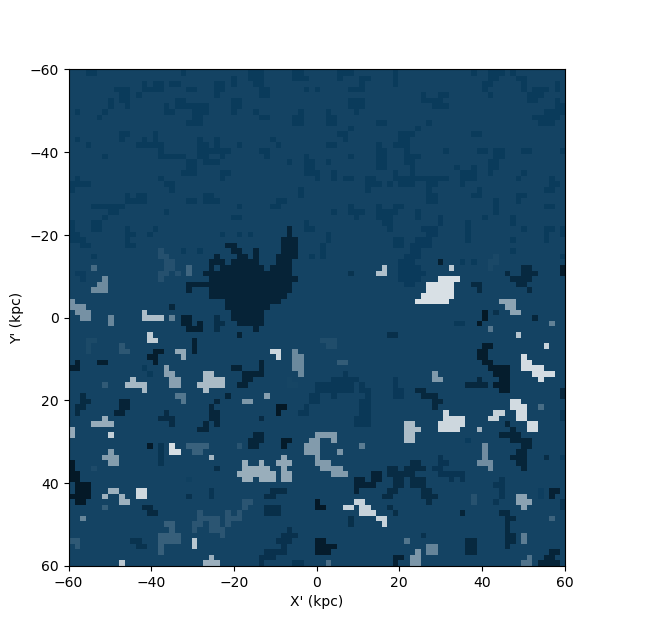

segmented_storm_2_d=82.5_a=129.8_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=82.5_a=129.8_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


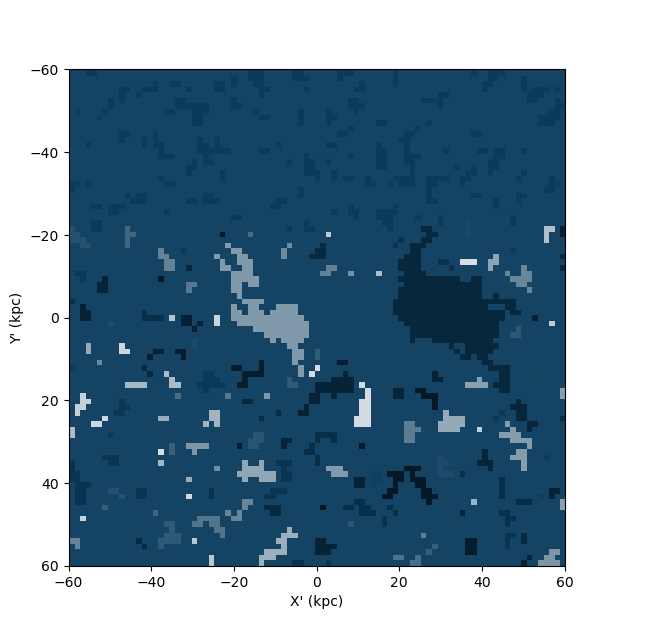

segmented_storm_2_d=85.0_a=352.3_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=85.0_a=352.3_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


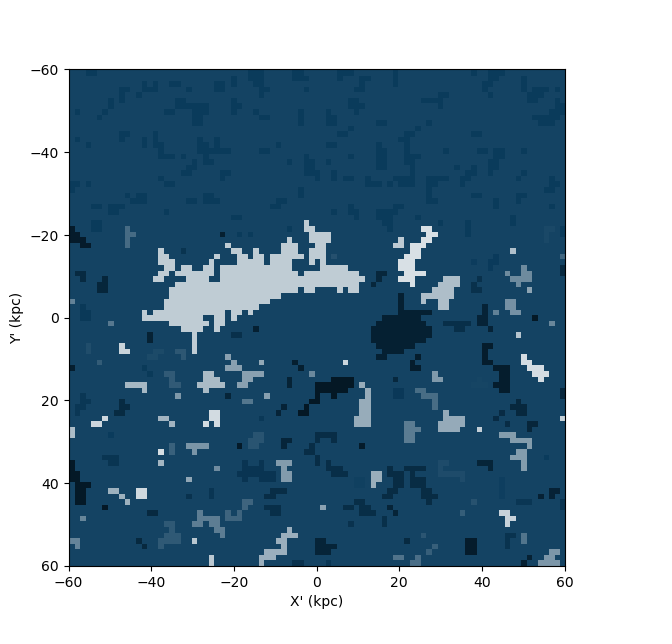

segmented_storm_2_d=87.5_a=214.8_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=87.5_a=214.8_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


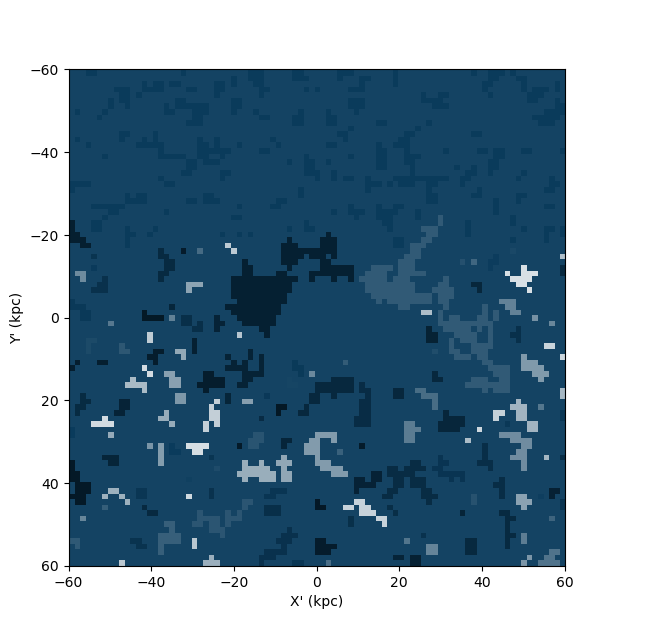

segmented_storm_2_d=90.0_a=77.3_pix=8000.fits
Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=90.0_a=77.3_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      48   ()      
  1  INPUT         1 ImageHDU        16   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        20   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        20   (89, 89)   int32   


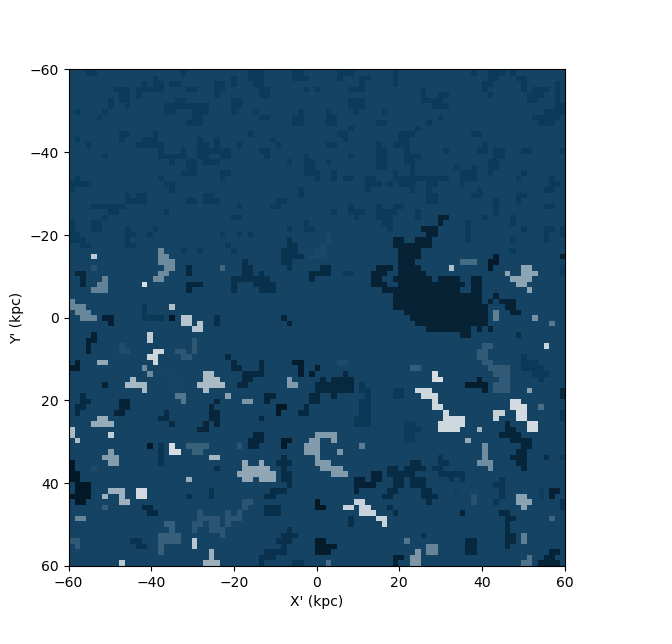

In [28]:
# display the Segment outputs
for file in sorted(segmented_path.iterdir()):
    if file.is_file():

        print(f'{file.name}')
        
        hdul = fits.open(f'{segmented_path}/{file.name}')
        hdul.info()
        image_data = hdul[3].data
        plt.figure(figsize=(8,8))

        # Custom blue colormap
        num_slices = 200
        base_color = "#0B3C5D"  # Lighter Steel Midnight Blue
        
        # 2. Generate the gradient bounds
        base_rgb = np.array(mcolors.to_rgb(base_color))
        white = np.array([1.0, 1.0, 1.0])
        black = np.array([0.0, 0.0, 0.0])
        
        # Light end: 15% base color + 85% white
        light_shade = base_rgb * 0.15 + white * 0.85
        
        # Dark end: Adjusted to 40% base + 60% black so it doesn't get too dark
        dark_shade = base_rgb * 0.40 + black * 0.60
        
        custom_gradient = mcolors.LinearSegmentedColormap.from_list(
            "single_color_gradient", [light_shade, base_rgb, dark_shade]
        )
        
        # 3. Extract the discrete shades as an array
        shuffled_cmap_base = custom_gradient.resampled(num_slices)
        color_list = shuffled_cmap_base(np.linspace(0, 1, num_slices))
        
        # 4. Scramble the shades randomly
        np.random.seed(42)  
        np.random.shuffle(color_list)
        
        # 5. Convert back into a discrete map
        shuffled_single_color_cmap = ListedColormap(color_list)

        plt.xlabel("X' (kpc)")
        plt.ylabel("Y' (kpc)")
        
        im = plt.imshow(image_data, extent=[-60,60,-60,60], \
                    cmap = shuffled_single_color_cmap, vmin = 0, vmax = 150)
        cbar = plt.colorbar(orientation='vertical')
        if cbar.solids is not None:
           cbar.solids.set_alpha(0)
        if hasattr(cbar, 'lines') and isinstance(cbar.lines, list):
           for line in cbar.lines:
               line.set_alpha(0)
        cbar.outline.set_alpha(0)
        cbar.ax.tick_params(axis='both', colors=(0,0,0,0), labelcolor=(0,0,0,0))
        plt.gca().invert_yaxis()
        plt.show()
        hdul.close()

In [10]:
# load the stream fitting outputs path
stfit_path = path(f'../stream_analysis/stfit_outputs/{galaxy_name}/fitted')

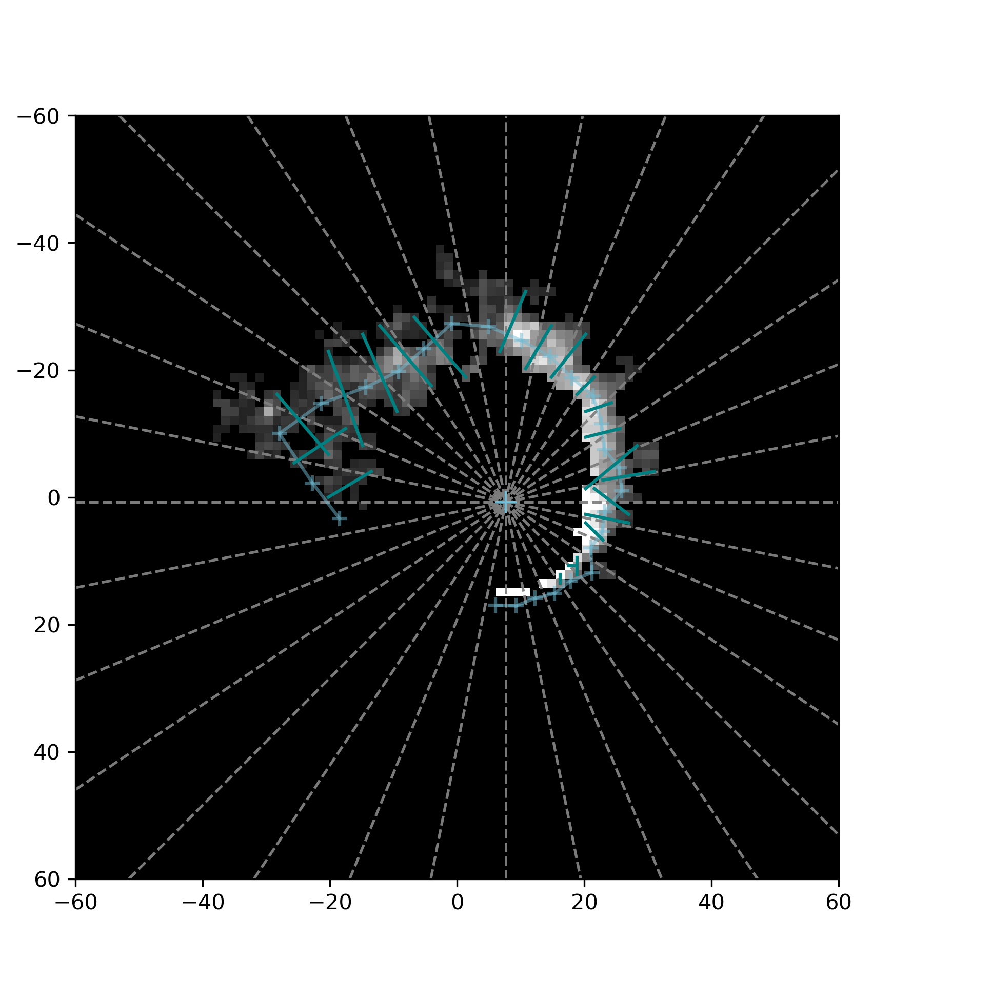

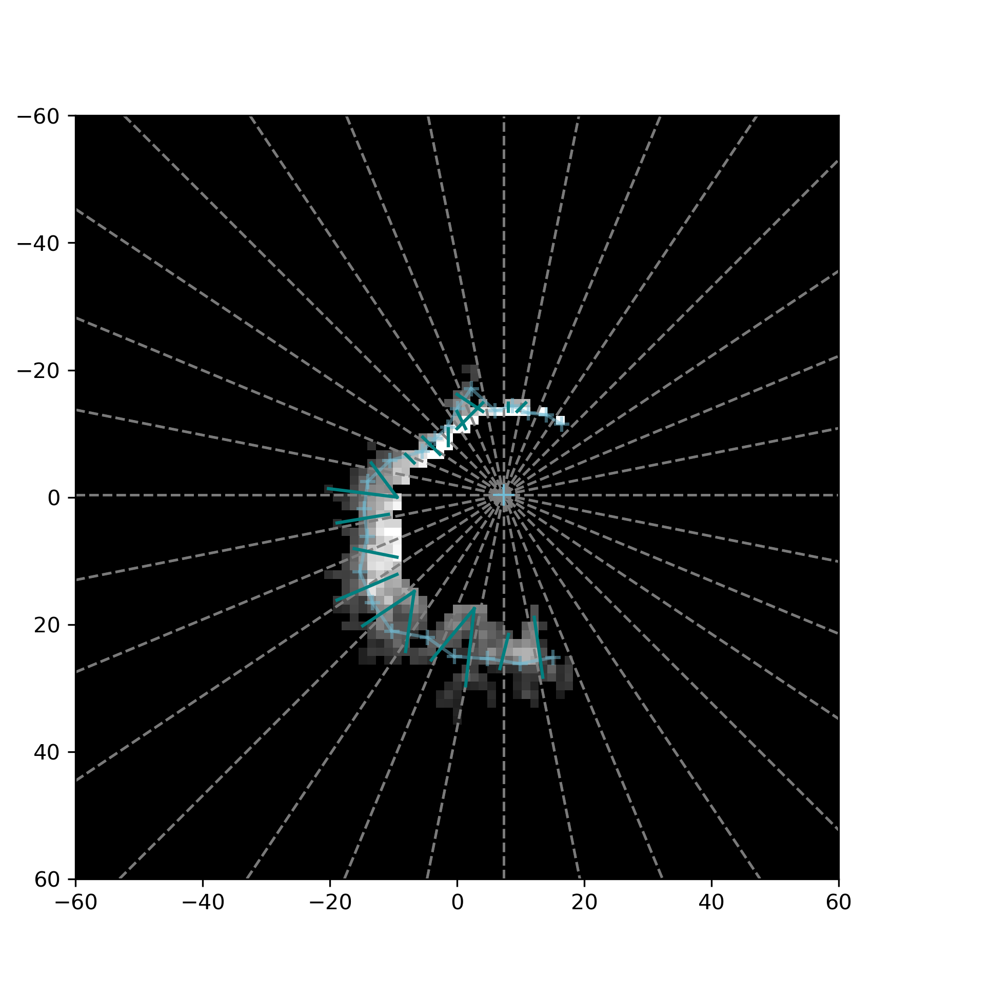

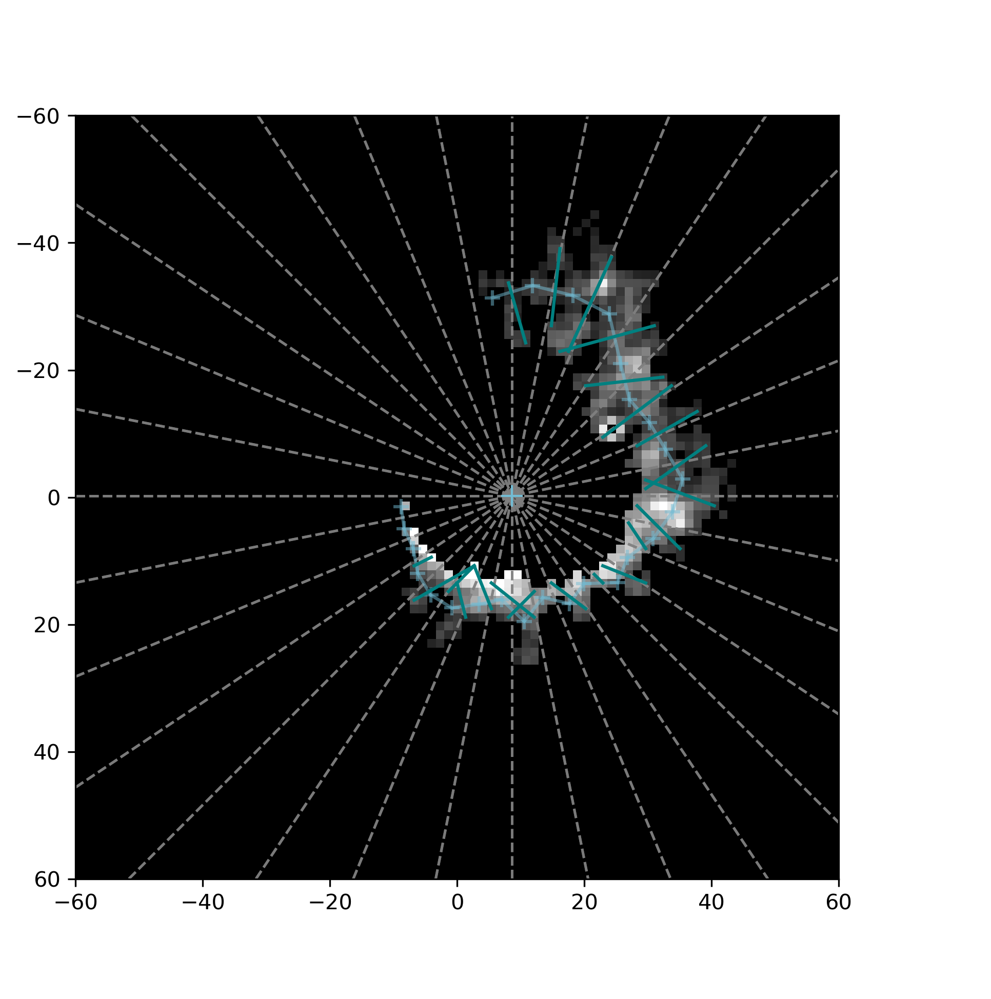

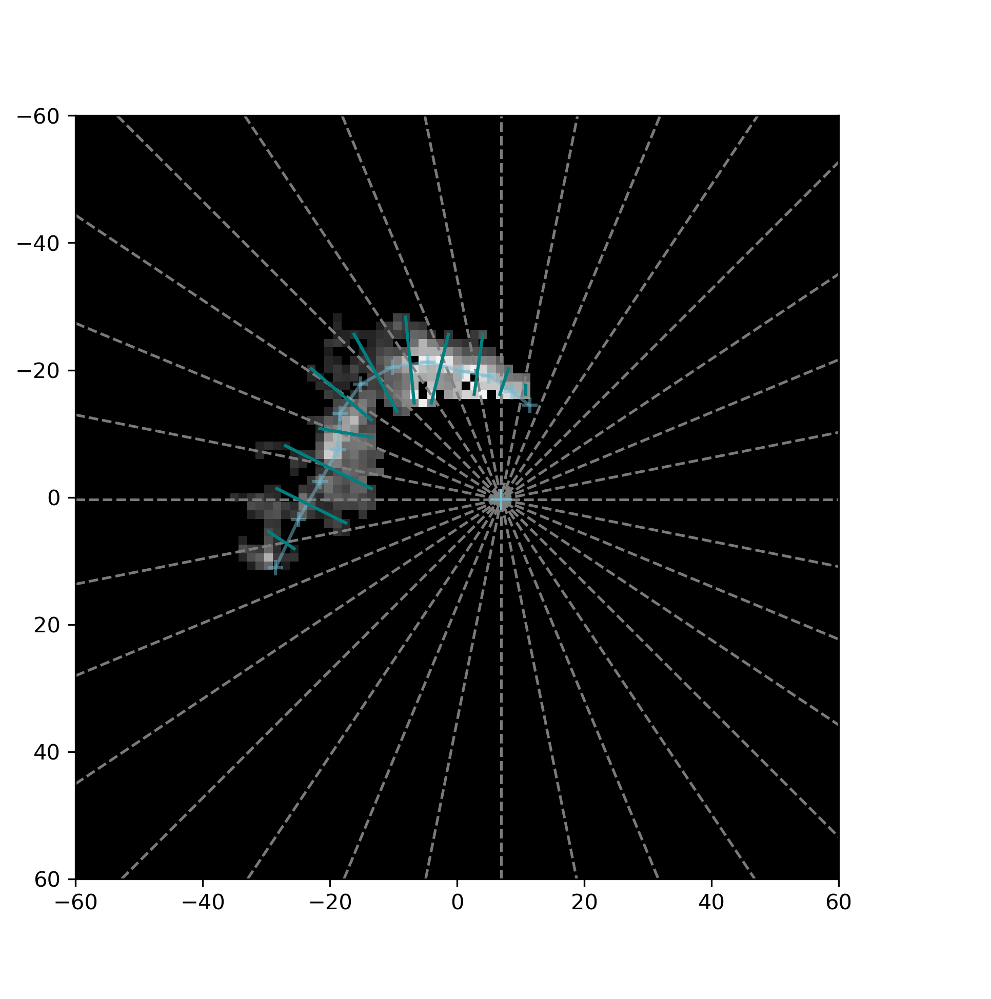

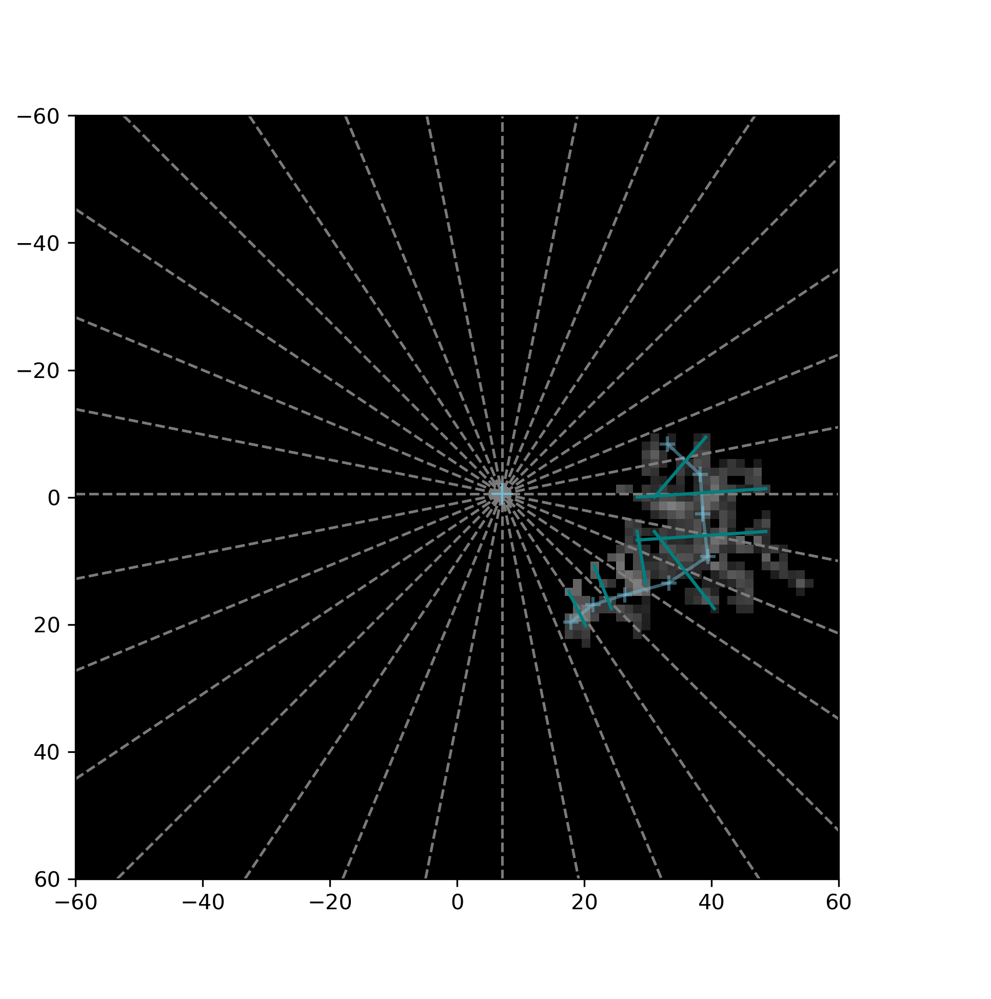

...

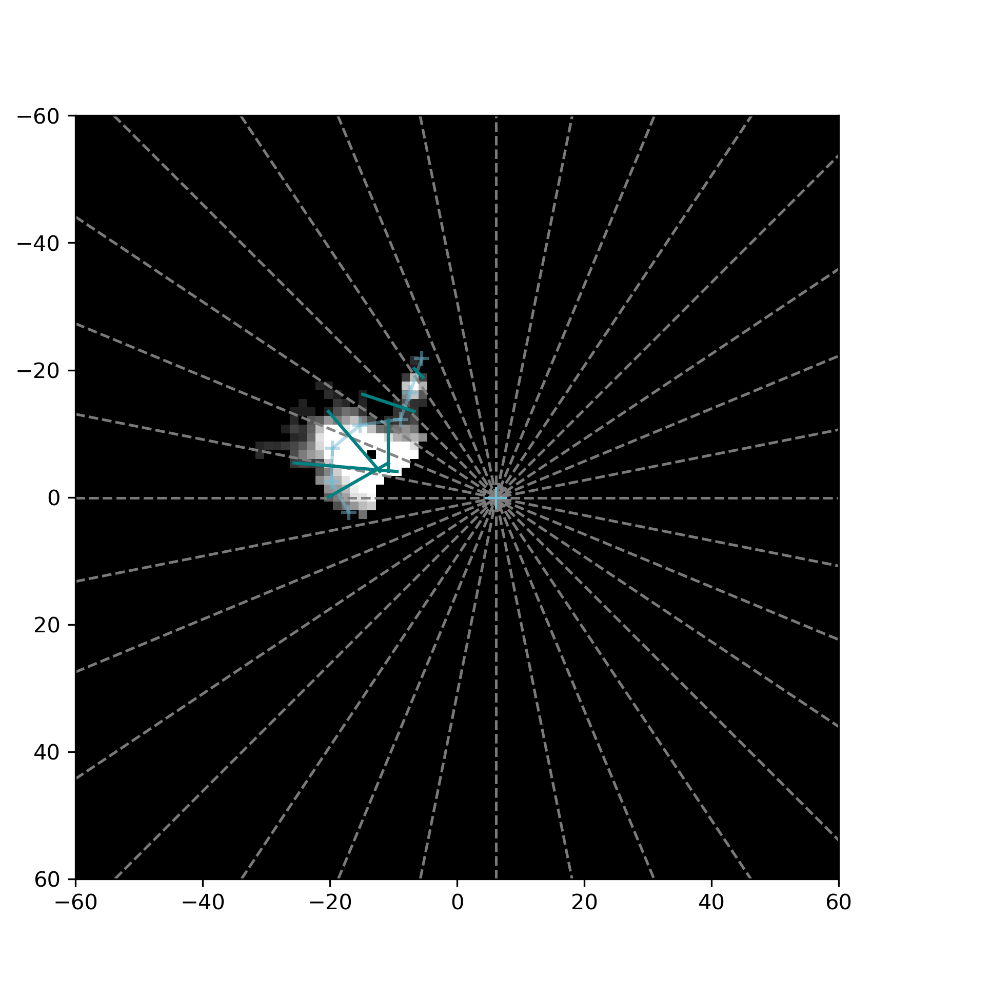

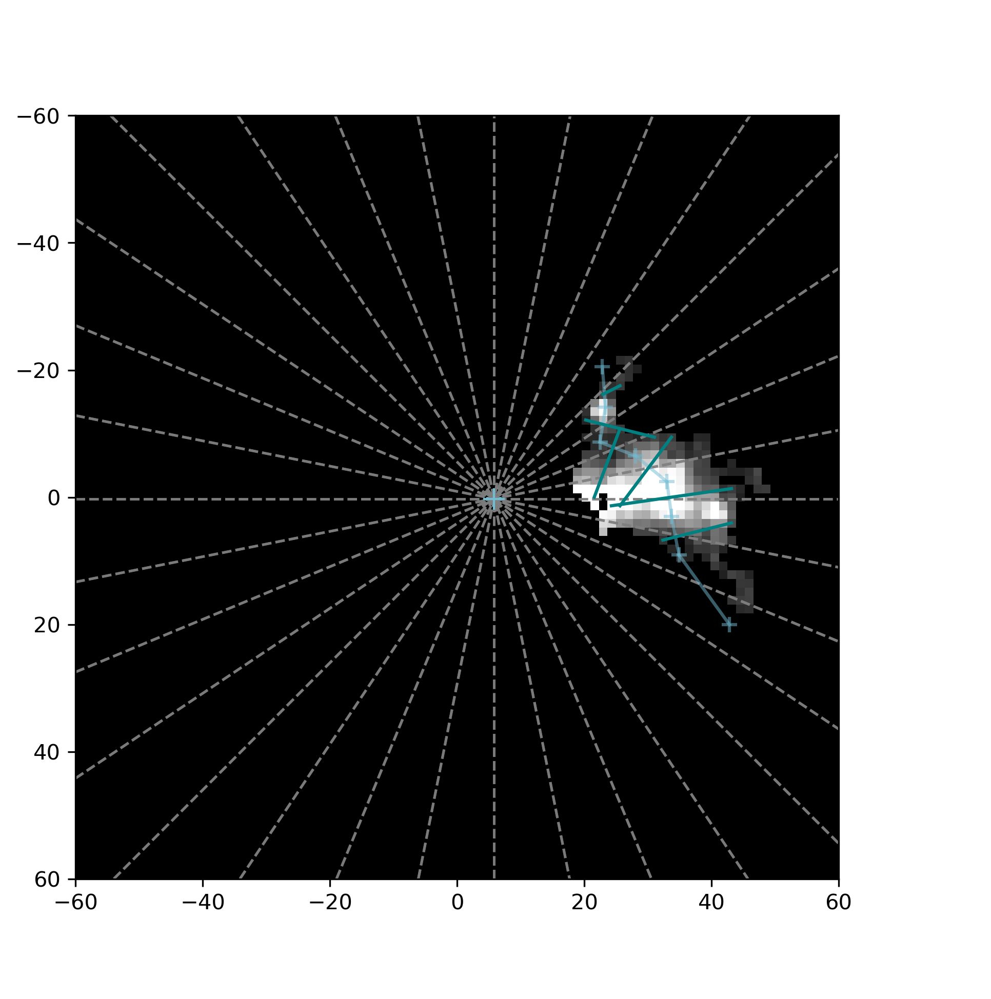

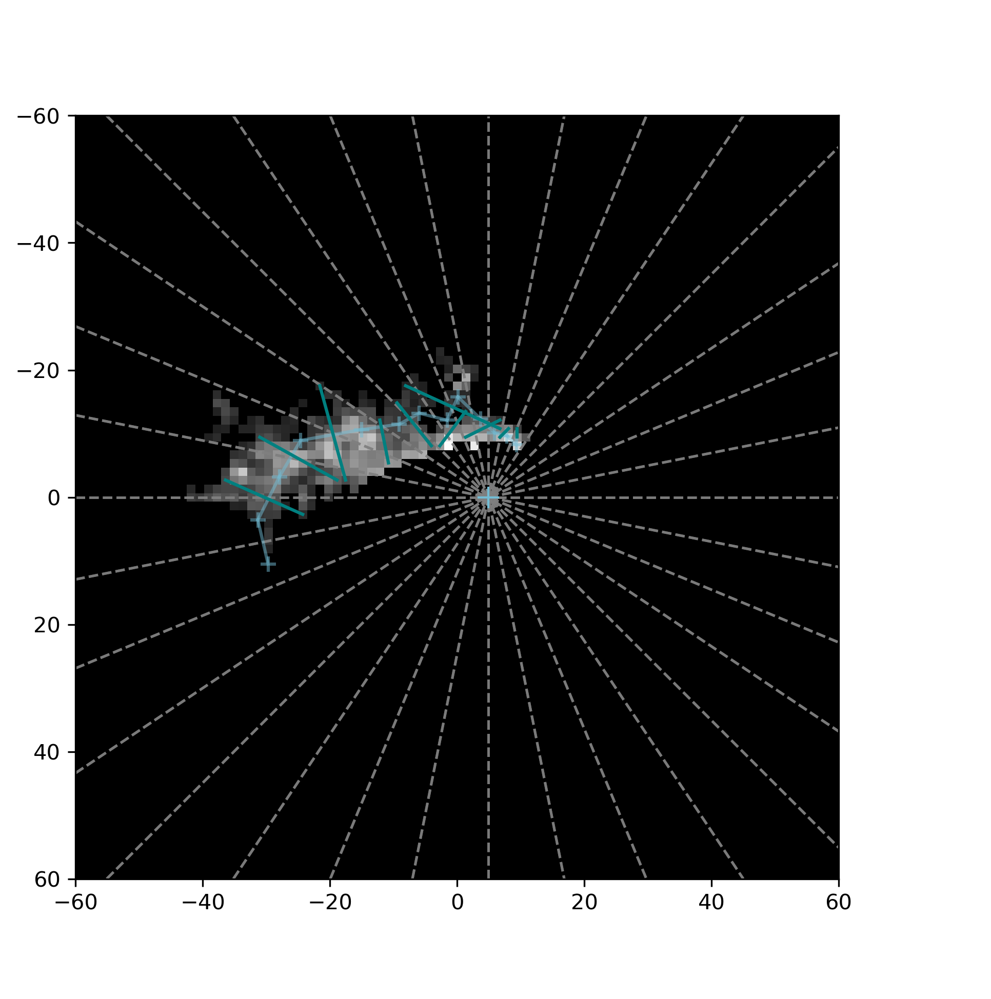

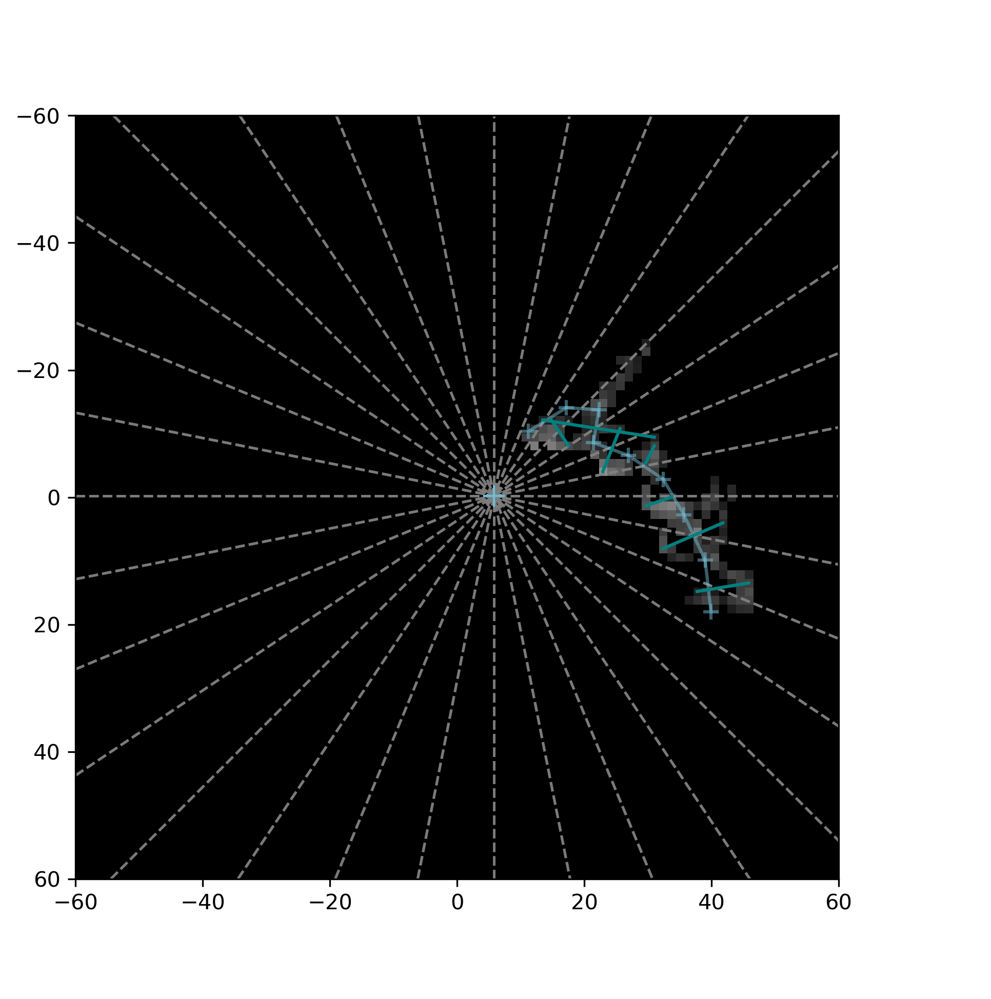

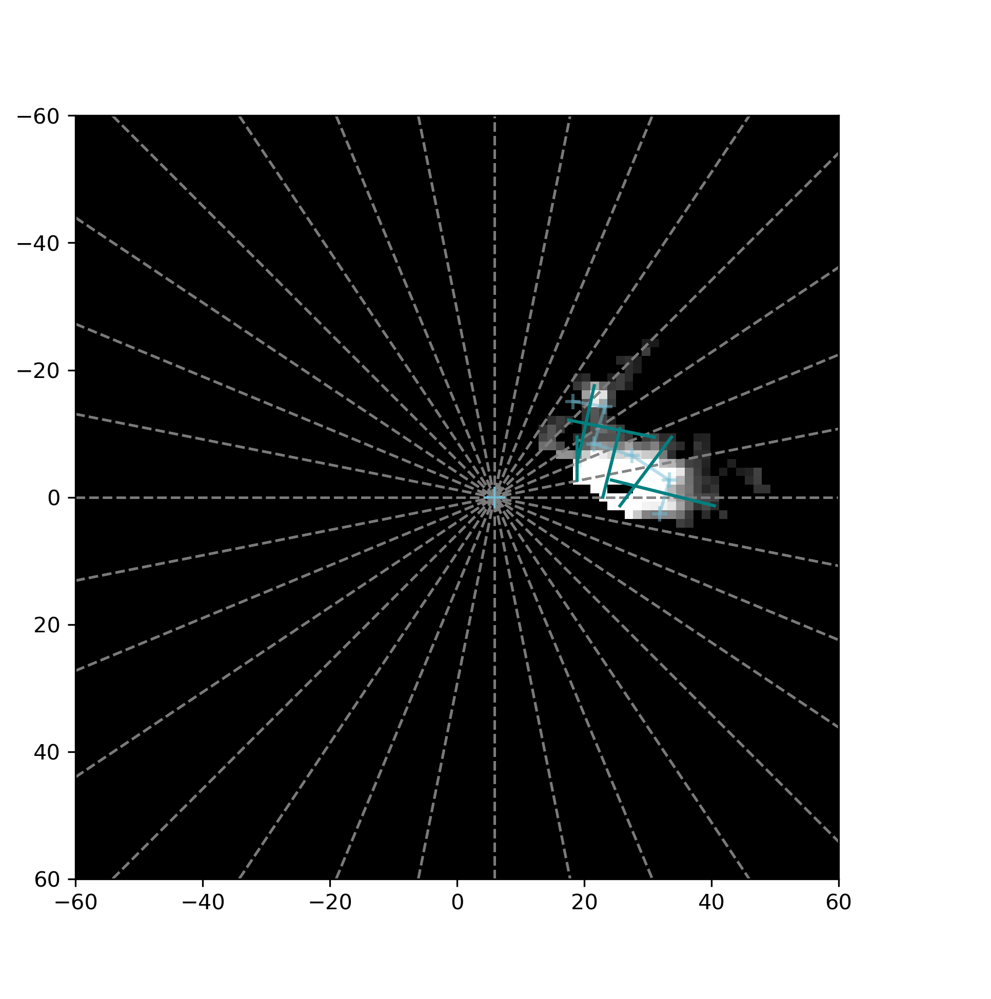

In [11]:
# display the stream fitting outputs
for file in sorted(stfit_path.iterdir()):
    if file.is_file():
        
        display(Image(filename=f'{stfit_path}/{file.name}'))

In [12]:
# load the stream length-to-width ratio vs declination path
lw_path = path(f'../stream_analysis/stfit_outputs/{galaxy_name}/lw_vs_dec.png')

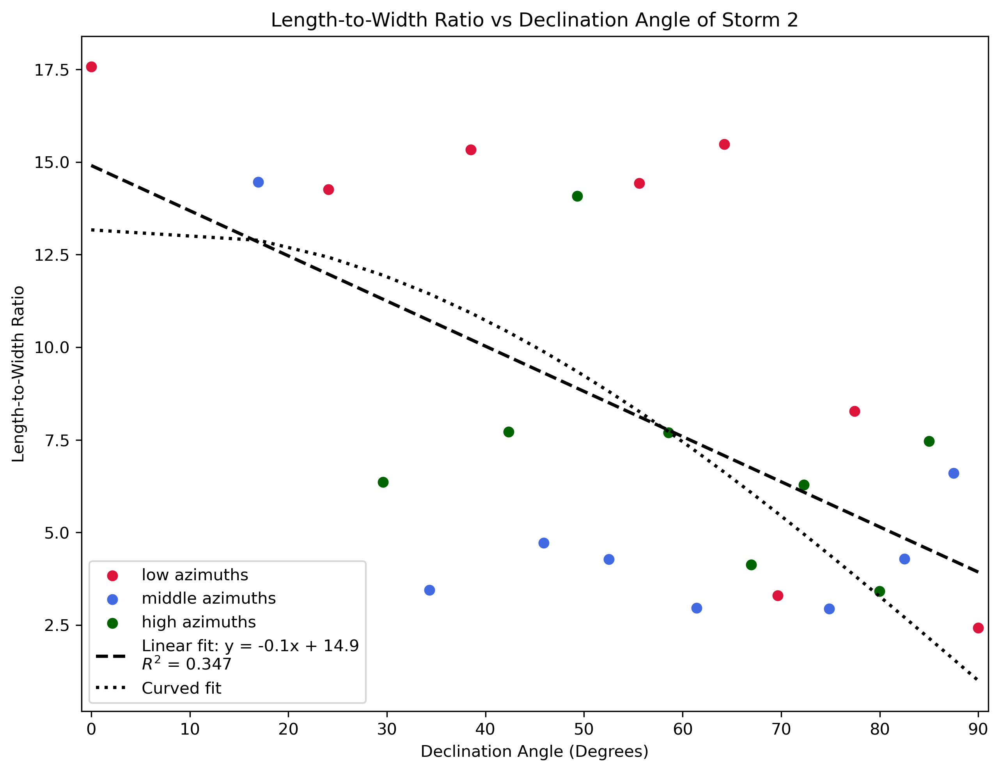

In [13]:
# display the stream length-to-width ratio vs declination
display(Image(filename=lw_path))

Filename: ../substructure_detection/sd_outputs/Segment/storm_2/segmented/segmented_storm_2_d=45.9_a=117.4_pix=8000.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  SEGMENT-CONFIG    1 PrimaryHDU      53   ()      
  1  INPUT-NO-SKY    1 ImageHDU         8   (89, 89)   float32   
  2  CLUMPS        1 ImageHDU        10   (89, 89)   int32   
  3  OBJECTS       1 ImageHDU        10   (89, 89)   int32   


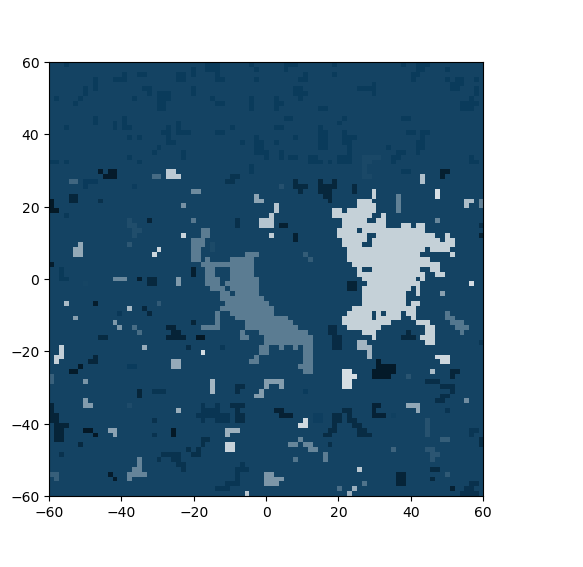

In [12]:
# # code to save individual images with a choice of axes and colorbar visibility
# my_extent = [-60,60,-60,60]

# hdul = fits.open(f'{segmented_path}/segmented_storm_2_d=45.9_a=117.4_pix=8000.fits')
# hdul.info()
# image_data = np.squeeze(hdul[3].data) # 0 for matched filter, 3 for segment
# plt.figure(figsize=(7,7))

# # custom blue colormap
# num_slices = 200
# base_color = "#0B3C5D"
# base_rgb = np.array(mcolors.to_rgb(base_color))
# white = np.array([1.0, 1.0, 1.0])
# black = np.array([0.0, 0.0, 0.0])
# light_shade = base_rgb * 0.15 + white * 0.85
# dark_shade = base_rgb * 0.40 + black * 0.60
# custom_gradient = mcolors.LinearSegmentedColormap.from_list(
#     "single_color_gradient", [light_shade, base_rgb, dark_shade]
# )
# shuffled_cmap_base = custom_gradient.resampled(num_slices)
# color_list = shuffled_cmap_base(np.linspace(0, 1, num_slices))
# np.random.seed(42)  
# np.random.shuffle(color_list)
# shuffled_single_color_cmap = ListedColormap(color_list)

# im = plt.imshow(image_data, extent=my_extent, \
#             cmap = shuffled_single_color_cmap, vmin = 0, vmax = 150, origin='lower')
# cbar = plt.colorbar(orientation='vertical')
# if cbar.solids is not None:
#      cbar.solids.set_alpha(0)
# if hasattr(cbar, 'lines') and isinstance(cbar.lines, list):
#      for line in cbar.lines:
#         line.set_alpha(0)
# cbar.outline.set_alpha(0)
# cbar.ax.tick_params(axis='both', colors=(0,0,0,0), labelcolor=(0,0,0,0))
# #cbar.set_label('Stellar Density Level', rotation=270, labelpad=15)
# plt.gca().xaxis.set_visible(True)
# plt.gca().yaxis.set_visible(True)
# plt.gca().spines['bottom'].set_visible(True)
# plt.savefig('../../Paper/Images/stream_fit/notables/segmented_storm_2_cut.png', dpi=300, bbox_inches='tight', transparent=True)
# plt.show()
# plt.close()